# COVID-19 Data Analysis with Python

**Project type:** Exploratory Data Analysis, Statistical Analysis & Data Visualization  
**Dataset:** Our World in Data COVID-19 compact dataset

This notebook analyzes global COVID-19 cases, deaths, testing and vaccination trends, with a separate analysis of Bangladesh.

> Run the notebook from the `notebooks/` directory. The expected dataset path is `/data/covid-data.csv`. All generated charts and reports are saved in the project folders.

## 1. Import Libraries

In [185]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set a consistent visual theme for all charts
sns.set_theme(style="whitegrid", palette="deep")

# Define the directory where visualization images will be saved
visualization_dir = "visualizations"

# Create the directory if it does not already exist
os.makedirs(visualization_dir, exist_ok=True)

# Define a reusable function to save and display charts
def save_chart(filename):

    # Build the complete output file path
    file_path = os.path.join(visualization_dir, filename)

    # Save the chart with high resolution
    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Display the chart in the notebook
    plt.show()

    # Print the saved file location
    print(f"Chart saved: {file_path}")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load Dataset

In [186]:
df = pd.read_csv("data/covid-data.csv")


print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

df.head()
df.info()

Total Rows: 629868
Total Columns: 61
<class 'pandas.DataFrame'>
RangeIndex: 629868 entries, 0 to 629867
Data columns (total 61 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   country                                     629868 non-null  str    
 1   date                                        629868 non-null  str    
 2   total_cases                                 617520 non-null  float64
 3   new_cases                                   612628 non-null  float64
 4   new_cases_smoothed                          611419 non-null  float64
 5   total_cases_per_million                     617520 non-null  float64
 6   new_cases_per_million                       612628 non-null  float64
 7   new_cases_smoothed_per_million              611419 non-null  float64
 8   total_deaths                                617520 non-null  float64
 9   new_deaths                                  

## 3. Data Understanding

In [187]:
# Display column names
print("Dataset columns:")
print(df.columns.tolist())

# Display data types and non-null counts
df.info()

# Display descriptive statistics for numeric columns
display(df.describe().T)

# Count countries and inspect the date range
print("Unique country labels:", df["country"].nunique())
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

# Display missing-value counts and percentages
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_report.head(20))

# Count exact duplicate rows and duplicate country-date combinations
print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate country-date combinations:",
    df.duplicated(subset=["country", "date"]).sum()
)

Dataset columns:
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccinations', 'new_vaccina

,count,mean,std,min,25%,50%,75%,max
total_cases,617520.0,1.538435e+07,7.785043e+07,0.000000,1.161675e+04,9.933300e+04,1.212156e+06,7.794521e+08
new_cases,612628.0,8.881605e+03,1.077630e+05,0.000000,0.000000e+00,0.000000e+00,2.200000e+01,8.401906e+06
new_cases_smoothed,611419.0,8.899207e+03,9.204700e+04,0.000000,0.000000e+00,1.428572e+00,1.101429e+02,6.402033e+06
total_cases_per_million,617520.0,1.421684e+05,1.815173e+05,0.000000,4.096433e+03,5.983708e+04,2.302997e+05,7.698068e+05
new_cases_per_million,612628.0,8.325794e+01,8.990955e+02,0.000000,0.000000e+00,0.000000e+00,2.202168e+00,2.307625e+05
new_cases_smoothed_per_million,611419.0,8.342587e+01,4.640098e+02,0.000000,0.000000e+00,1.918911e-01,1.779721e+01,3.746375e+04
total_deaths,617520.0,1.632331e+05,8.060507e+05,0.000000,9.200000e+01,1.250000e+03,1.412200e+04,7.117473e+06
new_deaths,613891.0,8.492375e+01,7.393160e+02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,5.716700e+04
new_deaths_smoothed,612679.0,8.509335e+01,6.810370e+02,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.482071e+04
total_deaths_per_million,617520.0,9.802750e+02,1.211068e+03,0.000000,5.471501e+01,4.567044e+02,1.572429e+03,6.604037e+03


Unique country labels: 262
Start date: 2020-01-01
End date: 2026-10-18


,missing_count,missing_percent
human_development_index,629868,100.00
weekly_icu_admissions,618875,98.25
weekly_icu_admissions_per_million,618875,98.25
excess_mortality_cumulative_per_million,615976,97.79
excess_mortality_cumulative_absolute,615942,97.79
excess_mortality_cumulative,615942,97.79
excess_mortality,615942,97.79
weekly_hosp_admissions_per_million,605371,96.11
weekly_hosp_admissions,605371,96.11
icu_patients_per_million,590752,93.79


Exact duplicate rows: 0
Duplicate country-date combinations: 0


## 4. Data Cleaning and Preprocessing

In [188]:
# Keep an untouched copy of the original data for reference
raw_df = df.copy()

# Remove columns that contain no values at all
empty_columns = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty_columns)

print("Completely empty columns removed:", empty_columns)

# Remove rows without a country label or date
df = df.dropna(subset=["country", "date"]).copy()

# Inspect duplicate country-date records before resolving them
duplicate_rows = df[df.duplicated(subset=["country", "date"], keep=False)]
print("Rows involved in duplicate country-date combinations:", len(duplicate_rows))

# Keep one record per country and date after sorting.
# This is a practical deduplication rule; inspect duplicate_rows if source conflicts matter.
df = (
    df.sort_values(["country", "date"])
      .drop_duplicates(subset=["country", "date"], keep="last")
      .reset_index(drop=True)
)

# Sort the cleaned dataset consistently
df = df.sort_values(["country", "date"]).reset_index(drop=True)

# Report negative daily values; these may reflect retrospective reporting corrections
for column in ["new_cases", "new_deaths", "new_vaccinations"]:
    if column in df.columns:
        negative_count = (df[column] < 0).sum()
        print(f"Negative values in {column}: {negative_count}")

# Do not automatically replace missing values or negative daily corrections with zero.
# Display the cleaned dataset dimensions and remaining missing values
print("Cleaned shape:", df.shape)
display(df.isna().sum().sort_values(ascending=False).head(15))

Completely empty columns removed: ['human_development_index']
Rows involved in duplicate country-date combinations: 0
Negative values in new_cases: 0
Negative values in new_deaths: 0
Negative values in new_vaccinations: 0
Cleaned shape: (629868, 60)


weekly_icu_admissions                      618875
weekly_icu_admissions_per_million          618875
excess_mortality_cumulative_per_million    615976
excess_mortality_cumulative_absolute       615942
excess_mortality_cumulative                615942
excess_mortality                           615942
weekly_hosp_admissions_per_million         605371
weekly_hosp_admissions                     605371
icu_patients                               590752
icu_patients_per_million                   590752
hosp_patients_per_million                  589212
hosp_patients                              589212
total_boosters                             571084
total_boosters_per_hundred                 571084
new_vaccinations                           560992
dtype: int64

In [194]:
# Save the cleaned dataset as a CSV file
# index=False prevents Pandas from saving the DataFrame index

df.to_csv("data/covid-cleaned-data.csv", index=False)

# Confirm that the cleaned dataset has been saved
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 5. Prepare Country-Level Data

In [189]:
# The OWID dataset includes aggregate rows such as continents and the world.
# Rows with a non-null continent are used as a practical country/territory-level subset.
if "continent" in df.columns:
    country_df = df[df["continent"].notna()].copy()
else:
    country_df = df.copy()

# Confirm the number of rows and country labels in the analysis subset
print("Country/territory-level rows:", len(country_df))
print("Country/territory labels:", country_df["country"].nunique())

# Create a latest available record for each country/territory
latest_by_country = (
    country_df.sort_values("date")
              .groupby("country", as_index=False)
              .tail(1)
              .copy()
)

# Display selected latest statistics when available
latest_columns = [
    col for col in [
        "country", "date", "total_cases", "total_deaths",
        "people_fully_vaccinated_per_hundred", "total_vaccinations"
    ] if col in latest_by_country.columns
]
display(latest_by_country[latest_columns].head())

Country/territory-level rows: 583844
Country/territory labels: 239


,country,date,total_cases,total_deaths,people_fully_vaccinated_per_hundred,total_vaccinations
612157,Western Sahara,2022-04-20,NaN,NaN,NaN,NaN
127742,Cote d'Ivoire,2023-02-19,NaN,NaN,40.020737,25263932.0
325813,Macao,2023-12-31,NaN,NaN,NaN,NaN
561313,Transnistria,2023-12-31,NaN,NaN,NaN,NaN
247644,Hong Kong,2024-08-12,NaN,NaN,NaN,NaN


## 6. Exploratory Data Analysis (EDA)

### 6.1 Global summary

In [190]:
# Calculate the latest available global aggregate row when present
world_rows = df[df["country"].astype(str).str.lower().eq("world")].sort_values("date")

if not world_rows.empty:
    # Use the latest reported World aggregate record
    latest_world = world_rows.iloc[-1]
    for metric in ["total_cases", "total_deaths", "total_vaccinations"]:
        if metric in df.columns:
            print(f"Latest reported global {metric}: {latest_world.get(metric)}")
    print("Global aggregate date:", latest_world["date"])
else:
    # If no World aggregate row exists, sum the latest country-level records
    print("No World aggregate row found; use country-level summaries instead.")
    for metric in ["total_cases", "total_deaths"]:
        if metric in latest_by_country.columns:
            print(f"Sum of latest country-level {metric}: {latest_by_country[metric].sum(min_count=1)}")

Latest reported global total_cases: 779452126.0
Latest reported global total_deaths: 7117473.0
Latest reported global total_vaccinations: nan
Global aggregate date: 2026-10-18


In [191]:
# Create a backup of the original dataset
# This protects the original data from accidental modifications

raw_df = df.copy()

# Display the original and backup dataset shapes
print("Original Dataset Shape:", df.shape)
print("Backup Dataset Shape:", raw_df.shape)

Original Dataset Shape: (629868, 60)
Backup Dataset Shape: (629868, 60)


### 6.2 Top 10 countries by reported cumulative cases

,country,date,total_cases
588620,United States,2026-10-18,103436829.0
114187,China,2026-10-18,99381761.0
255093,India,2026-10-18,45056221.0
193853,France,2026-10-18,39064913.0
208745,Germany,2026-10-18,38437953.0
79431,Brazil,2026-10-18,38058695.0
524595,South Korea,2026-10-18,34571873.0
277437,Japan,2026-10-18,33803572.0
272471,Italy,2026-10-18,26969918.0
586137,United Kingdom,2026-10-18,25143403.0


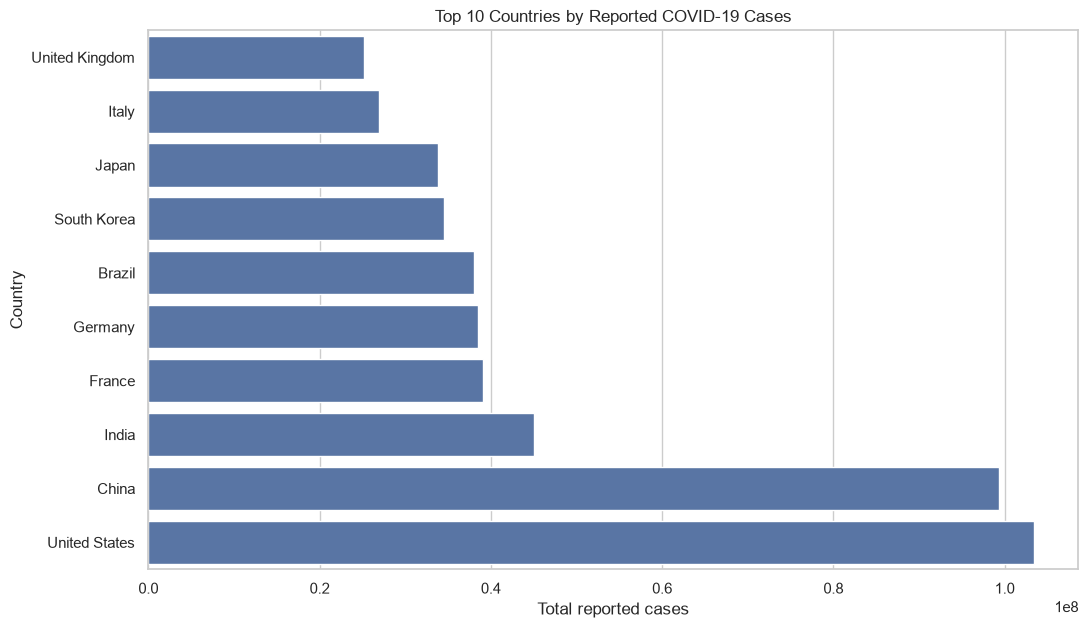

Chart saved: visualizations/top_10_countries_cases.png


In [193]:
# Select countries with available cumulative case counts
top_cases = (
    latest_by_country.dropna(subset=["total_cases"])
    .nlargest(10, "total_cases")[["country", "date", "total_cases"]]
    .sort_values("total_cases", ascending=True)
)

# Display the top 10 countries
display(top_cases.sort_values("total_cases", ascending=False))

# Plot the top 10 countries by cumulative cases
plt.figure(figsize=(12, 7))
sns.barplot(data=top_cases, x="total_cases", y="country")
plt.title("Top 10 Countries by Reported COVID-19 Cases")
plt.xlabel("Total reported cases")
plt.ylabel("Country")
save_chart("top_10_countries_cases.png")



## 6.3 Bangladesh analysis

In [47]:
# Filter records where country is Bangladesh
bangladesh_df = df[
    df["country"] == "Bangladesh"
].copy()

# Sort Bangladesh records chronologically
bangladesh_df = bangladesh_df.sort_values("date")

# Display the first five records
bangladesh_df.head()

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,continent,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand
47156,Bangladesh,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,169384891.0,1301.259033,24.99,74.264702,8676.755859,5.909079,13.2,71.816147,0.92
47157,Bangladesh,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,169384891.0,1301.259033,24.99,74.264702,8676.755859,5.909079,13.2,71.816147,0.92
47158,Bangladesh,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,169384891.0,1301.259033,24.99,74.264702,8676.755859,5.909079,13.2,71.816147,0.92
47159,Bangladesh,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,Asia,169384891.0,1301.259033,24.99,74.264702,8676.755859,5.909079,13.2,71.816147,0.92
47160,Bangladesh,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,Asia,169384891.0,1301.259033,24.99,74.264702,8676.755859,5.909079,13.2,71.816147,0.92


### 6.3.1 Bangladesh Total Cases and Deaths

In [48]:
# Get the latest available record for Bangladesh
latest_bangladesh = bangladesh_df.iloc[-1]

# Display the latest cumulative cases
print("Total Cases:", latest_bangladesh["total_cases"])

# Display the latest cumulative deaths
print("Total Deaths:", latest_bangladesh["total_deaths"])

# Display the latest reported population
print("Population:", latest_bangladesh["population"])

Total Cases: 2052280.0
Total Deaths: 29531.0
Population: 169384891.0


## 6.4 Calculate Death Rate

In [49]:
# Calculate the reported cumulative death rate
# Use NaN when total_cases is zero or missing to avoid division errors

df["death_rate"] = np.where(
    df["total_cases"] > 0,
    (df["total_deaths"] / df["total_cases"]) * 100,
    np.nan
)

# Display selected columns to verify the calculation
df[
    ["country", "date", "total_cases", "total_deaths", "death_rate"]
].head(10)

,country,date,total_cases,total_deaths,death_rate
0,Afghanistan,2020-01-01,NaN,NaN,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN
5,Afghanistan,2020-01-06,0.0,0.0,NaN
6,Afghanistan,2020-01-07,0.0,0.0,NaN
7,Afghanistan,2020-01-08,0.0,0.0,NaN
8,Afghanistan,2020-01-09,0.0,0.0,NaN
9,Afghanistan,2020-01-10,0.0,0.0,NaN


## 6.5 Global Daily New Cases

In [50]:
# Keep country-level records with a known continent
# This helps exclude aggregate rows such as World and Asia

country_level_df = df[
    df["continent"].notna()
].copy()

# Group country-level records by date
# Sum daily new cases for each date
# min_count=1 keeps the result missing if all values are missing

global_daily_cases = (
    country_level_df
    .groupby("date")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Rename the aggregated column for clarity
global_daily_cases = global_daily_cases.rename(
    columns={"new_cases": "global_new_cases"}
)

# Display the first five records
global_daily_cases.head()

,date,global_new_cases
0,2020-01-01,NaN
1,2020-01-02,NaN
2,2020-01-03,NaN
3,2020-01-04,3.0
4,2020-01-05,0.0


## 6.6 Monthly COVID-19 Cases

In [51]:
# Create a monthly period column from the date column
df["month"] = df["date"].dt.to_period("M")

# Group country-level records by month
# Sum new cases for each month

monthly_cases = (
    country_level_df
    .assign(month=country_level_df["date"].dt.to_period("M"))
    .groupby("month")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Display monthly cases
monthly_cases.head(10)

,month,new_cases
0,2020-01,9823.0
1,2020-02,74678.0
2,2020-03,697500.0
3,2020-04,2221858.0
4,2020-05,2888818.0
5,2020-06,4261987.0
6,2020-07,6967210.0
7,2020-08,8285836.0
8,2020-09,8632653.0
9,2020-10,11770202.0


## 6.7 Year-wise COVID-19 Cases

In [52]:
# Extract the year from the date column
df["year"] = df["date"].dt.year

# Keep country-level records to avoid counting aggregate regions
country_level_df = df[df["continent"].notna()].copy()

# Group records by year and calculate total new cases
yearly_cases = (
    country_level_df
    .groupby("year")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Rename the column for better readability
yearly_cases = yearly_cases.rename(
    columns={"new_cases": "total_new_cases"}
)

# Display yearly COVID-19 cases
yearly_cases

,year,total_new_cases
0,2020,82325027.0
1,2021,203066836.0
2,2022,444011107.0
3,2023,44402622.0
4,2024,3543568.0
5,2025,1679731.0
6,2026,437323.0


In [53]:
# Group country-level records by year
# Sum the reported new deaths for each year

yearly_deaths = (
    country_level_df
    .groupby("year")["new_deaths"]
    .sum(min_count=1)
    .reset_index()
)

# Rename the aggregated column
yearly_deaths = yearly_deaths.rename(
    columns={"new_deaths": "total_new_deaths"}
)

# Display yearly deaths
yearly_deaths

,year,total_new_deaths
0,2020,1936687.0
1,2021,3536795.0
2,2022,1248808.0
3,2023,297650.0
4,2024,69130.0
5,2025,26432.0
6,2026,8336.0


## 6.8 Monthly Cases in Bangladesh

In [54]:
# Create a monthly period column for Bangladesh
bangladesh_df["month"] = (
    bangladesh_df["date"].dt.to_period("M")
)

# Group Bangladesh records by month
# Sum the reported new cases for each month

bangladesh_monthly_cases = (
    bangladesh_df
    .groupby("month")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Rename the column
bangladesh_monthly_cases = bangladesh_monthly_cases.rename(
    columns={"new_cases": "monthly_new_cases"}
)

# Display the monthly case summary
bangladesh_monthly_cases.head(15)

,month,monthly_new_cases
0,2020-01,0.0
1,2020-02,0.0
2,2020-03,51.0
3,2020-04,7616.0
4,2020-05,39486.0
5,2020-06,98330.0
6,2020-07,92178.0
7,2020-08,75335.0
8,2020-09,50483.0
9,2020-10,44205.0


## 6.9 Find the Highest Daily Cases in Bangladesh

In [55]:
# Remove records where new_cases is missing
# Then find the row with the maximum new cases

highest_daily_cases = (
    bangladesh_df
    .dropna(subset=["new_cases"])
    .nlargest(1, "new_cases")
)

# Display the date and number of cases
highest_daily_cases[
    ["date", "new_cases", "total_cases"]
]

,date,new_cases,total_cases
47730,2021-07-28,16230.0,1210982.0


In [56]:
# Remove records where new_deaths is missing
# Then find the record with the highest daily deaths

highest_daily_deaths = (
    bangladesh_df
    .dropna(subset=["new_deaths"])
    .nlargest(1, "new_deaths")
)

# Display the date and death count
highest_daily_deaths[
    ["date", "new_deaths", "total_deaths"]
]

,date,new_deaths,total_deaths
47738,2021-08-05,264.0,21902.0


## 6.10 Vaccination Analysis

In [57]:
# Get Bangladesh vaccination records
# Keep only rows where vaccination data is available

bangladesh_vaccination = bangladesh_df.dropna(
    subset=["people_vaccinated", "people_fully_vaccinated"]
).copy()

# Select the latest available vaccination record
latest_vaccination = (
    bangladesh_vaccination
    .sort_values("date")
    .tail(1)
)

# Display important vaccination information
latest_vaccination[
    [
        "date",
        "total_vaccinations",
        "people_vaccinated",
        "people_fully_vaccinated",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred"
    ]
]

,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
48776,2024-06-08,361742530.0,151507170.0,142201680.0,89.445496,83.95181


## 6.11 Correlation Analysis

In [58]:
# Select numerical columns relevant to COVID-19 analysis
correlation_columns = [
    "total_cases",
    "total_deaths",
    "new_cases",
    "new_deaths",
    "total_vaccinations",
    "people_fully_vaccinated",
    "population",
    "population_density",
    "median_age",
    "life_expectancy"
]

# Calculate the correlation matrix
correlation_matrix = df[correlation_columns].corr()

# Display the correlation matrix
correlation_matrix.round(2)

,total_cases,total_deaths,new_cases,new_deaths,total_vaccinations,people_fully_vaccinated,population,population_density,median_age,life_expectancy
total_cases,1.00,0.97,0.22,0.18,0.86,0.85,0.75,-0.03,0.07,0.06
total_deaths,0.97,1.00,0.29,0.30,0.85,0.85,0.79,-0.03,0.06,0.05
new_cases,0.22,0.29,1.00,0.56,0.28,0.29,0.28,-0.01,0.03,0.02
new_deaths,0.18,0.30,0.56,1.00,0.19,0.19,0.42,-0.02,0.03,0.03
total_vaccinations,0.86,0.85,0.28,0.19,1.00,1.00,0.88,-0.06,-0.07,-0.08
people_fully_vaccinated,0.85,0.85,0.29,0.19,1.00,1.00,0.88,-0.06,-0.09,-0.10
population,0.75,0.79,0.28,0.42,0.88,0.88,1.00,-0.03,-0.01,-0.01
population_density,-0.03,-0.03,-0.01,-0.02,-0.06,-0.06,-0.03,1.00,0.19,0.19
median_age,0.07,0.06,0.03,0.03,-0.07,-0.09,-0.01,0.19,1.00,0.77
life_expectancy,0.06,0.05,0.02,0.03,-0.08,-0.10,-0.01,0.19,0.77,1.00


## 7. Feature Engineering

### 7.1 — Create Death Rate Feature

In [59]:
# Calculate cumulative reported death rate
# Replace invalid or unavailable ratios with NaN

df["death_rate"] = (
    df["total_deaths"]
    .div(df["total_cases"].where(df["total_cases"] > 0))
    .mul(100)
)

# Display the newly created feature
df[
    ["country", "date", "total_cases", "total_deaths", "death_rate"]
].head(10)

,country,date,total_cases,total_deaths,death_rate
0,Afghanistan,2020-01-01,NaN,NaN,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN
5,Afghanistan,2020-01-06,0.0,0.0,NaN
6,Afghanistan,2020-01-07,0.0,0.0,NaN
7,Afghanistan,2020-01-08,0.0,0.0,NaN
8,Afghanistan,2020-01-09,0.0,0.0,NaN
9,Afghanistan,2020-01-10,0.0,0.0,NaN


### 7.2 — Create Recovery Proxy

In [60]:
# Calculate confirmed cases excluding reported deaths
# This is NOT the actual recovered cases

df["cases_excluding_deaths"] = (
    df["total_cases"] - df["total_deaths"]
)

# Display the new feature
df[
    ["country", "date", "total_cases", "total_deaths",
     "cases_excluding_deaths"]
].head(10)

,country,date,total_cases,total_deaths,cases_excluding_deaths
0,Afghanistan,2020-01-01,NaN,NaN,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN
3,Afghanistan,2020-01-04,0.0,0.0,0.0
4,Afghanistan,2020-01-05,0.0,0.0,0.0
5,Afghanistan,2020-01-06,0.0,0.0,0.0
6,Afghanistan,2020-01-07,0.0,0.0,0.0
7,Afghanistan,2020-01-08,0.0,0.0,0.0
8,Afghanistan,2020-01-09,0.0,0.0,0.0
9,Afghanistan,2020-01-10,0.0,0.0,0.0


### 7.3 — Create Monthly and Year Features

In [61]:
# Extract month number from the date
df["month_number"] = df["date"].dt.month

# Extract month name from the date
df["month_name"] = df["date"].dt.month_name()

# Extract year from the date
df["year"] = df["date"].dt.year

# Display the new date-related features
df[
    ["date", "year", "month_number", "month_name"]
].head(10)

,date,year,month_number,month_name
0,2020-01-01,2020,1,January
1,2020-01-02,2020,1,January
2,2020-01-03,2020,1,January
3,2020-01-04,2020,1,January
4,2020-01-05,2020,1,January
5,2020-01-06,2020,1,January
6,2020-01-07,2020,1,January
7,2020-01-08,2020,1,January
8,2020-01-09,2020,1,January
9,2020-01-10,2020,1,January


In [63]:
# Save the dataset containing cleaned data and engineered features
df.to_csv(
    "data/covid-analysis-ready.csv",
    index=False
)

# Confirm successful export
print("Analysis-ready dataset saved successfully!")
print("Final Shape:", df.shape)

Analysis-ready dataset saved successfully!
Final Shape: (629868, 66)


In [68]:
# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Import os to manage project directories
import os

# Set a consistent visual theme for all charts
sns.set_theme(style="whitegrid", palette="deep")

# Define the directory where visualization images will be saved
visualization_dir = "visualizations"

# Create the directory if it does not already exist
os.makedirs(visualization_dir, exist_ok=True)

# Define a reusable function to save and display charts
def save_chart(filename):

    # Build the complete output file path
    file_path = os.path.join(visualization_dir, filename)

    # Save the chart with high resolution
    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Display the chart in the notebook
    plt.show()

    # Print the saved file location
    print(f"Chart saved: {file_path}")

In [69]:
# Select country-level records only
# This excludes aggregate records such as World, Asia and Europe
country_level_df = df[df["continent"].notna()].copy()

# Group records by date and calculate total reported new cases
# min_count=1 keeps the result NaN if all values for a date are missing
global_daily_cases = (
    country_level_df
    .groupby("date")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Sort the records chronologically
global_daily_cases = global_daily_cases.sort_values("date")

# Calculate the 7-day rolling average of daily new cases
global_daily_cases["7_day_average"] = (
    global_daily_cases["new_cases"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Display the first 10 records
global_daily_cases.head(10)

,date,new_cases,7_day_average
0,2020-01-01,NaN,NaN
1,2020-01-02,NaN,NaN
2,2020-01-03,NaN,NaN
3,2020-01-04,3.0,NaN
4,2020-01-05,0.0,NaN
5,2020-01-06,3.0,NaN
6,2020-01-07,0.0,NaN
7,2020-01-08,1.0,NaN
8,2020-01-09,0.0,NaN
9,2020-01-10,0.0,1.0


### 7.4 --- Global COVID-19 Cases Trend

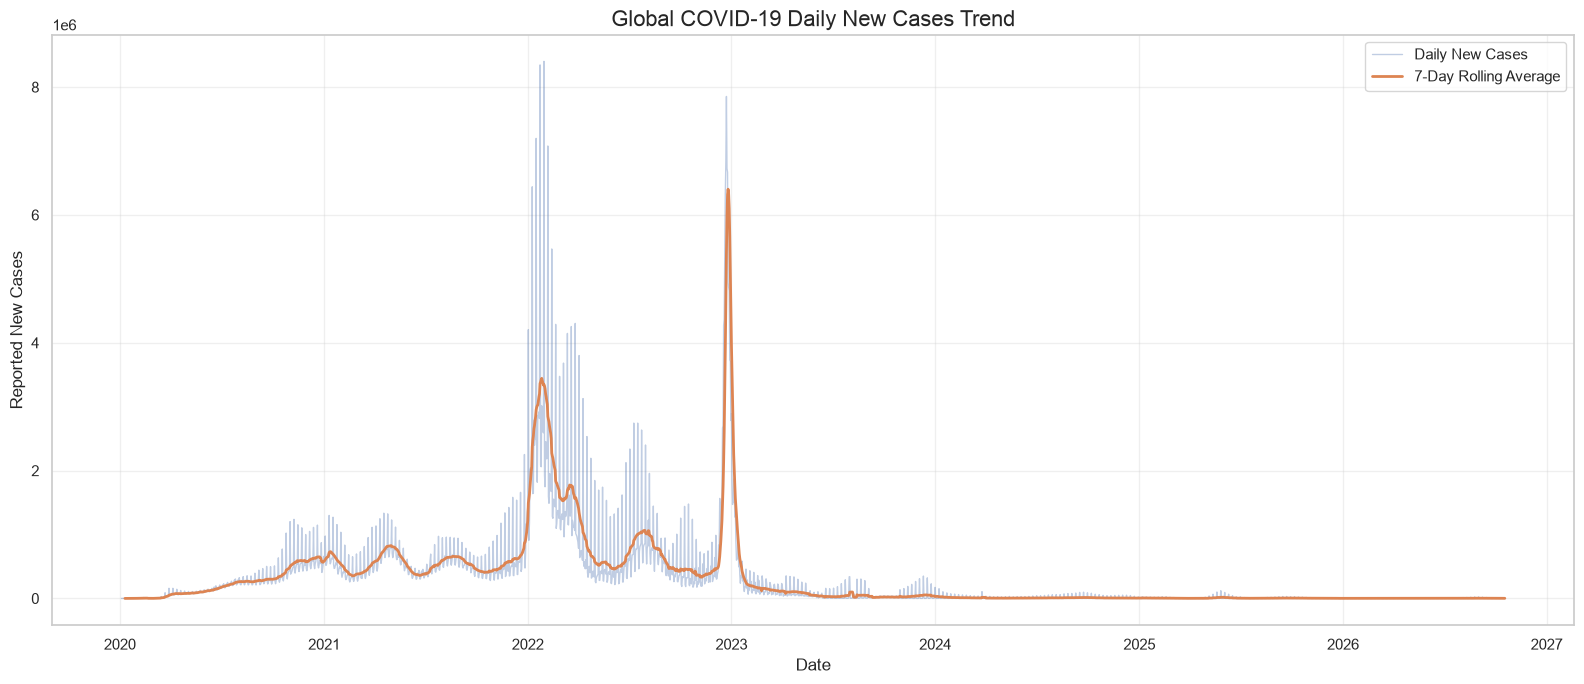

Chart saved: visualizations/global_cases_trend.png


In [70]:
# Set the chart size
plt.figure(figsize=(16, 7))

# Plot the daily reported cases
plt.plot(
    global_daily_cases["date"],
    global_daily_cases["new_cases"],
    label="Daily New Cases",
    alpha=0.35,
    linewidth=1
)

# Plot the 7-day rolling average
plt.plot(
    global_daily_cases["date"],
    global_daily_cases["7_day_average"],
    label="7-Day Rolling Average",
    linewidth=2
)

# Add a descriptive chart title
plt.title(
    "Global COVID-19 Daily New Cases Trend",
    fontsize=16
)

# Add labels to both axes
plt.xlabel("Date", fontsize=12)
plt.ylabel("Reported New Cases", fontsize=12)

# Display the legend
plt.legend()

# Add grid lines for easier interpretation
plt.grid(True, alpha=0.3)

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Save and display the visualization
save_chart("global_cases_trend.png")

### 7.5 — Top 10 Countries by Total Cases

In [71]:
# Select country-level records and exclude aggregate regions
country_level_df = df[df["continent"].notna()].copy()

# Group death records by date and calculate total reported daily deaths
global_daily_deaths = (
    country_level_df
    .groupby("date")["new_deaths"]
    .sum(min_count=1)
    .reset_index()
)

# Sort records by date
global_daily_deaths = global_daily_deaths.sort_values("date")

# Calculate the 7-day rolling average of daily deaths
global_daily_deaths["7_day_average"] = (
    global_daily_deaths["new_deaths"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Display the first 10 records
global_daily_deaths.head(10)

,date,new_deaths,7_day_average
0,2020-01-01,NaN,NaN
1,2020-01-02,NaN,NaN
2,2020-01-03,NaN,NaN
3,2020-01-04,0.0,NaN
4,2020-01-05,3.0,NaN
5,2020-01-06,0.0,NaN
6,2020-01-07,0.0,NaN
7,2020-01-08,0.0,NaN
8,2020-01-09,0.0,NaN
9,2020-01-10,0.0,0.428571


### 7.6 - Global Covid-19 Daily Deaths

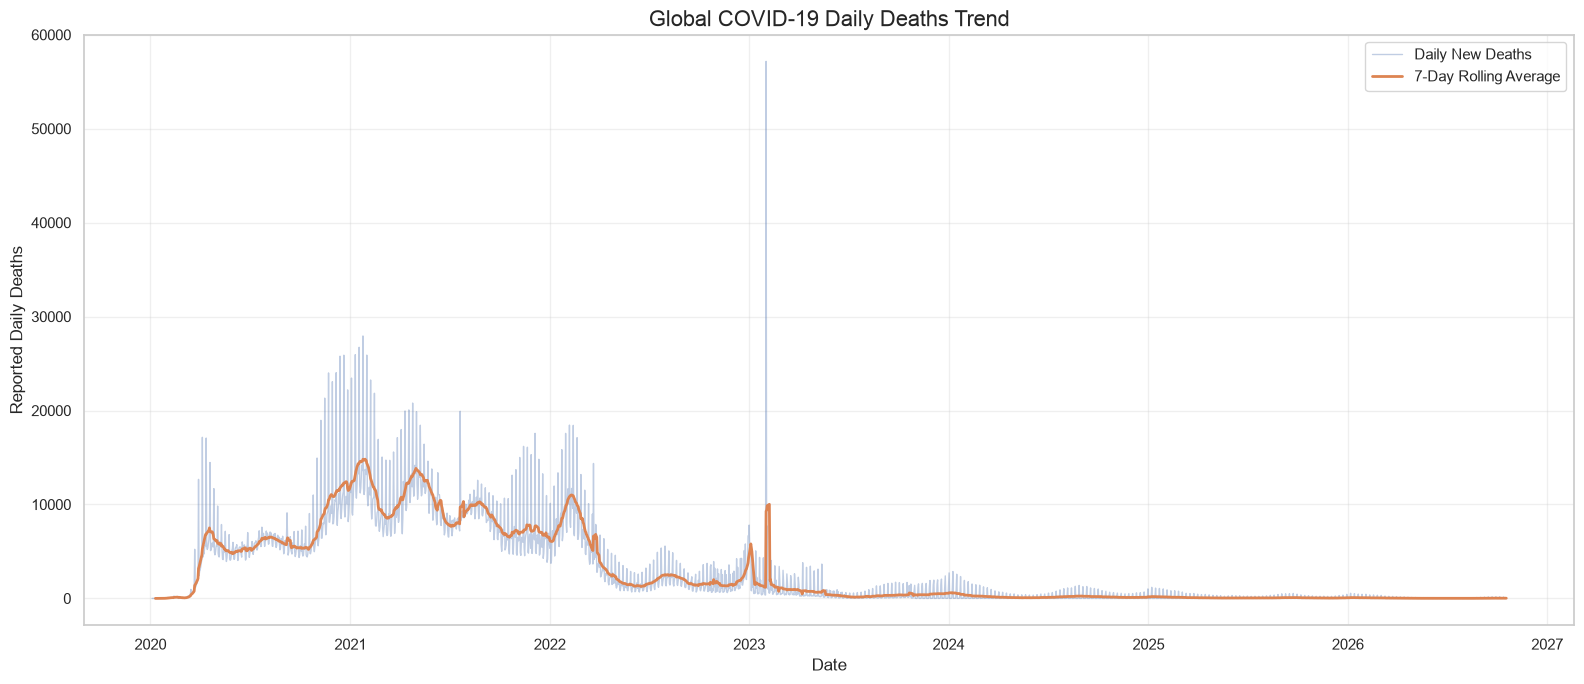

Chart saved: visualizations/global_deaths_trend.png


In [72]:
# Set the chart dimensions
plt.figure(figsize=(16, 7))

# Plot daily reported deaths
plt.plot(
    global_daily_deaths["date"],
    global_daily_deaths["new_deaths"],
    label="Daily New Deaths",
    alpha=0.35,
    linewidth=1
)

# Plot the 7-day rolling average
plt.plot(
    global_daily_deaths["date"],
    global_daily_deaths["7_day_average"],
    label="7-Day Rolling Average",
    linewidth=2
)

# Add chart title
plt.title(
    "Global COVID-19 Daily Deaths Trend",
    fontsize=16
)

# Add axis labels
plt.xlabel("Date", fontsize=12)
plt.ylabel("Reported Daily Deaths", fontsize=12)

# Display the legend
plt.legend()

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("global_deaths_trend.png")

In [73]:
# Find the index of the maximum daily reported deaths
peak_death_index = global_daily_deaths["new_deaths"].idxmax()

# Retrieve the record for the peak date
peak_death_record = global_daily_deaths.loc[peak_death_index]

# Print the peak date and reported death count
print("Peak Death Date:", peak_death_record["date"])
print("Maximum Daily Deaths:", peak_death_record["new_deaths"])

Peak Death Date: 2023-02-01 00:00:00
Maximum Daily Deaths: 57167.0


In [74]:
# Define the date of the unusually high global death count
peak_date = pd.Timestamp("2023-02-01")

# Filter country-level records for the peak date
peak_day_data = country_level_df[
    country_level_df["date"] == peak_date
].copy()

# Sort countries by reported new deaths in descending order
peak_day_countries = peak_day_data.sort_values(
    by="new_deaths",
    ascending=False
)

# Display the top 10 countries contributing to reported deaths
peak_day_countries[
    ["country", "date", "new_deaths"]
].head(10)

,country,date,new_deaths
112832,China,2023-02-01,44047.0
276082,Japan,2023-02-01,9903.0
35868,Australia,2023-02-01,1040.0
523240,South Korea,2023-02-01,1026.0
440013,Philippines,2023-02-01,351.0
391472,New Zealand,2023-02-01,146.0
78076,Brazil,2023-02-01,133.0
271116,Italy,2023-02-01,115.0
331907,Malaysia,2023-02-01,76.0
584782,United Kingdom,2023-02-01,61.0


In [75]:
# Find the index of the maximum 7-day rolling average
peak_average_index = global_daily_deaths["7_day_average"].idxmax()

# Retrieve the corresponding record
peak_average_record = global_daily_deaths.loc[peak_average_index]

# Display the peak date and average deaths
print("Peak 7-Day Average Date:", peak_average_record["date"])
print("Peak 7-Day Average Deaths:", peak_average_record["7_day_average"])

Peak 7-Day Average Date: 2021-01-28 00:00:00
Peak 7-Day Average Deaths: 14820.714285714286


In [76]:
# Sort country records by date
sorted_df = country_level_df.sort_values("date")

# Get the latest available record for each country
latest_country_data = (
    sorted_df
    .groupby("country")
    .tail(1)
    .copy()
)

# Select countries with available cumulative death data
latest_deaths = latest_country_data.dropna(
    subset=["total_deaths"]
)

# Sort countries by cumulative deaths in descending order
top_10_deaths = latest_deaths.sort_values(
    by="total_deaths",
    ascending=False
).head(10)

# Display country, date and total reported deaths
top_10_deaths[
    ["country", "date", "total_deaths"]
]

,country,date,total_deaths
588620,United States,2026-10-18,1240149.0
79431,Brazil,2026-10-18,704109.0
255093,India,2026-10-18,533849.0
461226,Russia,2026-10-18,404290.0
355597,Mexico,2026-10-18,335205.0
586137,United Kingdom,2026-10-18,232612.0
438885,Peru,2026-10-18,221073.0
272471,Italy,2026-10-18,198523.0
208745,Germany,2026-10-18,174979.0
193853,France,2026-10-18,168207.0


### 7.7 - Top 10 Countries by Total COVID-19 Deaths

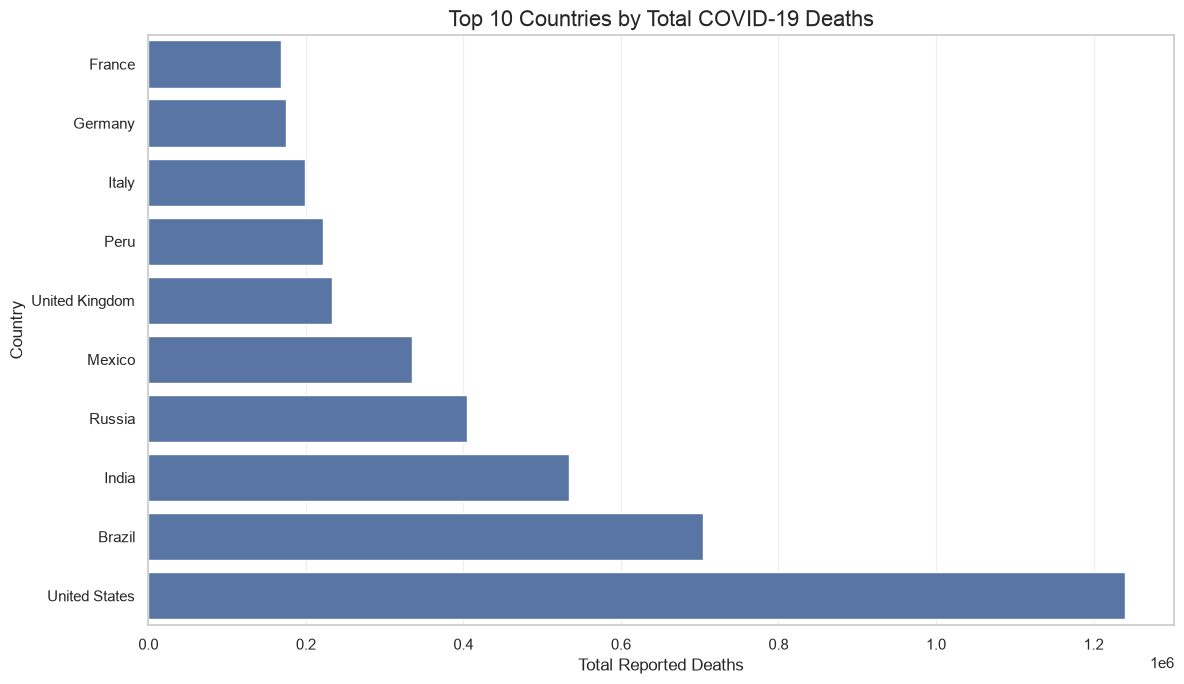

Chart saved: visualizations/top_10_countries_deaths.png


In [77]:
# Create a figure with a suitable size
plt.figure(figsize=(12, 7))

# Sort the data in ascending order for horizontal bar plotting
plot_data = top_10_deaths.sort_values(
    by="total_deaths",
    ascending=True
)

# Create a horizontal bar chart
sns.barplot(
    data=plot_data,
    x="total_deaths",
    y="country"
)

# Add chart title
plt.title(
    "Top 10 Countries by Total COVID-19 Deaths",
    fontsize=16
)

# Add axis labels
plt.xlabel("Total Reported Deaths", fontsize=12)
plt.ylabel("Country", fontsize=12)

# Add chart grid for easier comparison
plt.grid(axis="x", alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("top_10_countries_deaths.png")

In [79]:
# Sort country records by date
sorted_df = country_level_df.sort_values("date")

# Get the latest available record for each country
latest_country_data = (
    sorted_df
    .groupby("country")
    .tail(1)
    .copy()
)

# Remove countries where cumulative cases are missing
latest_cases = latest_country_data.dropna(
    subset=["total_cases"]
)

# Sort countries by cumulative reported cases
top_10_cases = latest_cases.sort_values(
    by="total_cases",
    ascending=False
).head(10)

# Display the top 10 countries
top_10_cases[
    ["country", "date", "total_cases"]
]

,country,date,total_cases
588620,United States,2026-10-18,103436829.0
114187,China,2026-10-18,99381761.0
255093,India,2026-10-18,45056221.0
193853,France,2026-10-18,39064913.0
208745,Germany,2026-10-18,38437953.0
79431,Brazil,2026-10-18,38058695.0
524595,South Korea,2026-10-18,34571873.0
277437,Japan,2026-10-18,33803572.0
272471,Italy,2026-10-18,26969918.0
586137,United Kingdom,2026-10-18,25143403.0


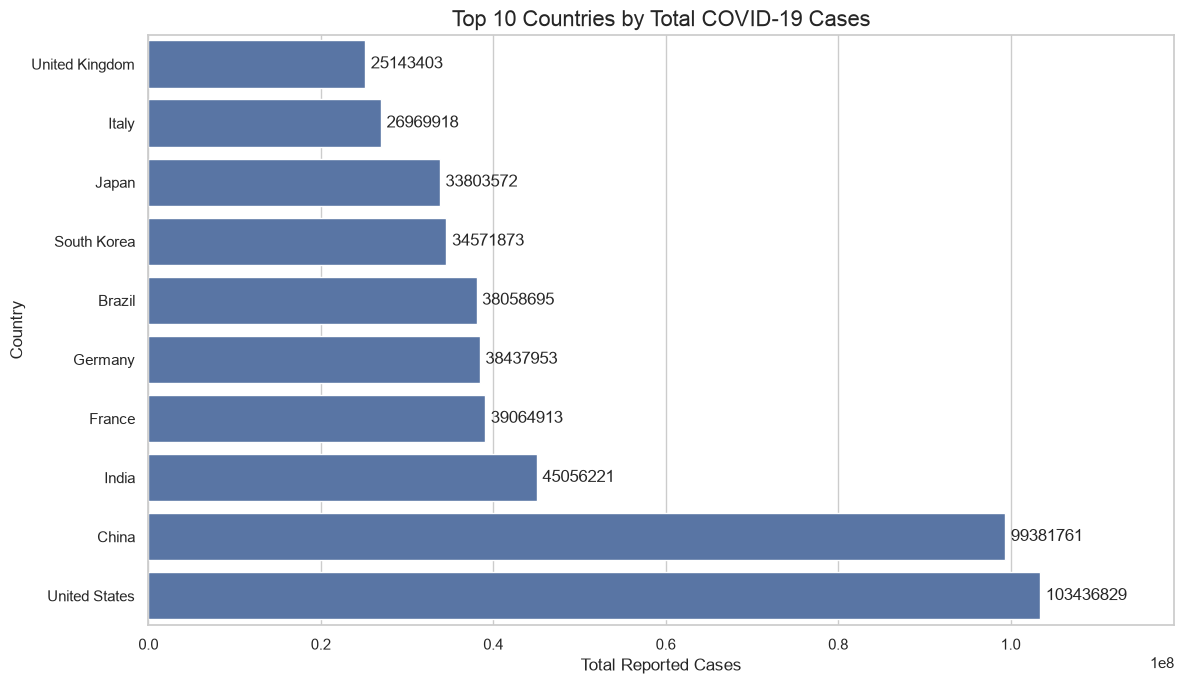

Chart saved: visualizations/top_10_countries_cases.png


In [80]:
# Create a figure with suitable dimensions
plt.figure(figsize=(12, 7))

# Sort data in ascending order for horizontal bars
plot_data = top_10_cases.sort_values(
    by="total_cases",
    ascending=True
)

# Create the horizontal bar chart
ax = sns.barplot(
    data=plot_data,
    x="total_cases",
    y="country"
)

# Add case counts at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4
    )

# Add chart title
plt.title(
    "Top 10 Countries by Total COVID-19 Cases",
    fontsize=16
)

# Add axis labels
plt.xlabel("Total Reported Cases", fontsize=12)
plt.ylabel("Country", fontsize=12)

# Add space on the right for data labels
plt.xlim(0, plot_data["total_cases"].max() * 1.15)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("top_10_countries_cases.png")

In [82]:
# Export the top 10 countries by reported cases
top_10_cases[
    ["country", "date", "total_cases"]
].to_csv(
    "reports/top_10_countries_cases.csv",
    index=False
)

# Export the top 10 countries by reported deaths
top_10_deaths[
    ["country", "date", "total_deaths"]
].to_csv(
    "reports/top_10_countries_deaths.csv",
    index=False
)

# Confirm that both files have been saved
print("Top 10 cases and deaths reports saved successfully.")

Top 10 cases and deaths reports saved successfully.


### 7.8 - Bangladesh COVID-19 Cases Analysis

In [83]:
# Filter the dataset to keep only Bangladesh records
bangladesh_df = df[
    df["country"] == "Bangladesh"
].copy()

# Sort Bangladesh records chronologically
bangladesh_df = bangladesh_df.sort_values("date")

# Select date and daily new cases
bangladesh_cases = bangladesh_df[
    ["date", "new_cases"]
].copy()

# Display the first 10 records
bangladesh_cases.head(10)

,date,new_cases
47156,2020-01-01,NaN
47157,2020-01-02,NaN
47158,2020-01-03,NaN
47159,2020-01-04,0.0
47160,2020-01-05,0.0
47161,2020-01-06,0.0
47162,2020-01-07,0.0
47163,2020-01-08,0.0
47164,2020-01-09,0.0
47165,2020-01-10,0.0


In [84]:
# Set date as the DataFrame index
bangladesh_cases = bangladesh_cases.set_index("date")

# Create a continuous daily date index
# Missing dates will receive NaN instead of being treated as zero
bangladesh_cases = bangladesh_cases.asfreq("D")

# Calculate the 7-calendar-day rolling average
bangladesh_cases["7_day_average"] = (
    bangladesh_cases["new_cases"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Reset the date index
bangladesh_cases = bangladesh_cases.reset_index()

# Display the processed data
bangladesh_cases.head(10)

,date,new_cases,7_day_average
0,2020-01-01,NaN,NaN
1,2020-01-02,NaN,NaN
2,2020-01-03,NaN,NaN
3,2020-01-04,0.0,NaN
4,2020-01-05,0.0,NaN
5,2020-01-06,0.0,NaN
6,2020-01-07,0.0,NaN
7,2020-01-08,0.0,NaN
8,2020-01-09,0.0,NaN
9,2020-01-10,0.0,0.0


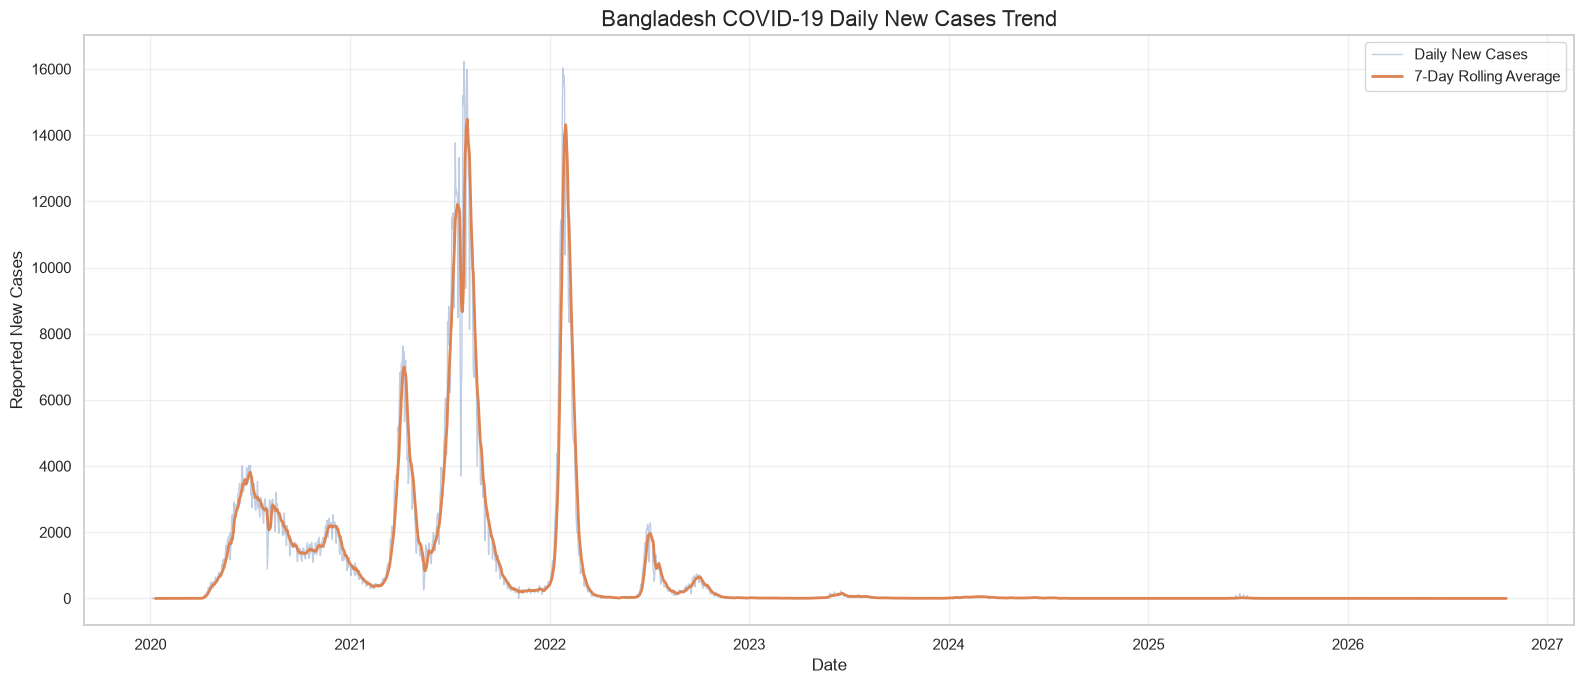

Chart saved: visualizations/bangladesh_cases_trend.png


In [85]:
# Create a figure with suitable dimensions
plt.figure(figsize=(16, 7))

# Plot daily reported COVID-19 cases in Bangladesh
plt.plot(
    bangladesh_cases["date"],
    bangladesh_cases["new_cases"],
    label="Daily New Cases",
    alpha=0.35,
    linewidth=1
)

# Plot the 7-day rolling average
plt.plot(
    bangladesh_cases["date"],
    bangladesh_cases["7_day_average"],
    label="7-Day Rolling Average",
    linewidth=2
)

# Add chart title
plt.title(
    "Bangladesh COVID-19 Daily New Cases Trend",
    fontsize=16
)

# Add axis labels
plt.xlabel("Date", fontsize=12)
plt.ylabel("Reported New Cases", fontsize=12)

# Display the legend
plt.legend()

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("bangladesh_cases_trend.png")

In [86]:
# Find the index of the maximum daily reported cases
peak_cases_index = bangladesh_cases["new_cases"].idxmax()

# Retrieve the record for the peak date
peak_cases_record = bangladesh_cases.loc[peak_cases_index]

# Display the peak date and case count
print("Peak Cases Date:", peak_cases_record["date"])
print("Maximum Daily Cases:", peak_cases_record["new_cases"])

Peak Cases Date: 2021-07-28 00:00:00
Maximum Daily Cases: 16230.0


In [87]:
# Export Bangladesh daily cases and rolling average to CSV
bangladesh_cases.to_csv(
    "reports/bangladesh_cases_analysis.csv",
    index=False
)

# Confirm successful export
print("Bangladesh cases analysis saved successfully.")

Bangladesh cases analysis saved successfully.


In [88]:
# Create a copy of Bangladesh data
bangladesh_monthly = bangladesh_df.copy()

# Convert each date into a monthly period
bangladesh_monthly["month"] = (
    bangladesh_monthly["date"].dt.to_period("M")
)

# Group daily cases by month and calculate monthly totals
monthly_cases = (
    bangladesh_monthly
    .groupby("month")["new_cases"]
    .sum(min_count=1)
    .reset_index()
)

# Convert monthly periods into timestamps for plotting
monthly_cases["month"] = monthly_cases["month"].dt.to_timestamp()

# Display the monthly data
monthly_cases.head(10)

,month,new_cases
0,2020-01-01,0.0
1,2020-02-01,0.0
2,2020-03-01,51.0
3,2020-04-01,7616.0
4,2020-05-01,39486.0
5,2020-06-01,98330.0
6,2020-07-01,92178.0
7,2020-08-01,75335.0
8,2020-09-01,50483.0
9,2020-10-01,44205.0


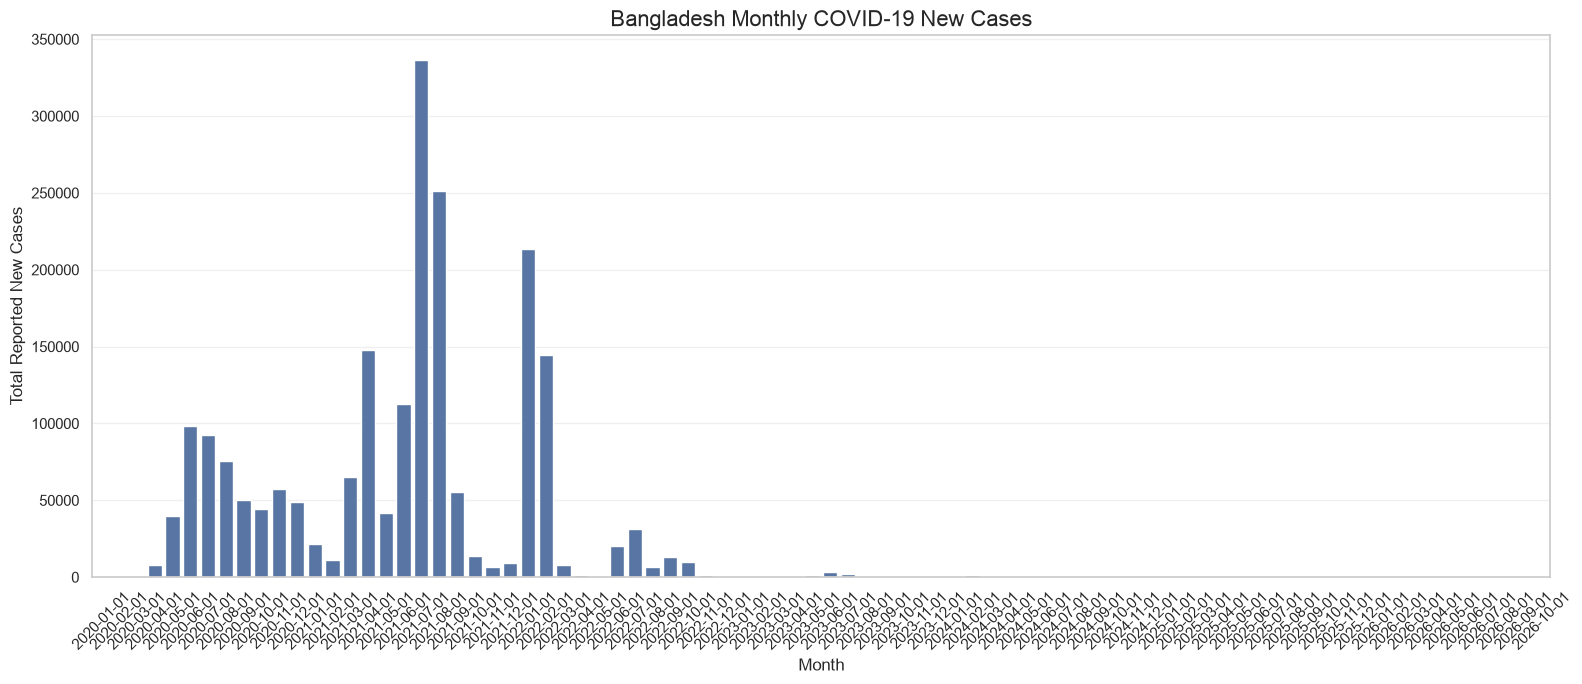

Chart saved: visualizations/bangladesh_monthly_cases.png


In [89]:
# Create a figure with suitable dimensions
plt.figure(figsize=(16, 7))

# Create a bar chart showing monthly reported cases
sns.barplot(
    data=monthly_cases,
    x="month",
    y="new_cases"
)

# Add chart title
plt.title(
    "Bangladesh Monthly COVID-19 New Cases",
    fontsize=16
)

# Add axis labels
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Reported New Cases", fontsize=12)

# Rotate date labels for readability
plt.xticks(rotation=45)

# Add grid lines to the y-axis
plt.grid(axis="y", alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("bangladesh_monthly_cases.png")

In [90]:
# Find the index of the month with the highest reported cases
peak_month_index = monthly_cases["new_cases"].idxmax()

# Retrieve the peak month record
peak_month_record = monthly_cases.loc[peak_month_index]

# Display the peak month and case count
print("Peak Month:", peak_month_record["month"])
print("Total Reported Cases:", peak_month_record["new_cases"])

Peak Month: 2021-07-01 00:00:00
Total Reported Cases: 336226.0


In [91]:
# Export monthly Bangladesh cases to a CSV file
monthly_cases.to_csv(
    "reports/bangladesh_monthly_cases.csv",
    index=False
)

# Confirm successful export
print("Bangladesh monthly cases report saved successfully.")

Bangladesh monthly cases report saved successfully.


In [92]:
# Create a copy of Bangladesh records for vaccination analysis
bangladesh_vaccination = bangladesh_df.copy()

# Select the date and vaccination-related columns
vaccination_columns = [
    "date",
    "total_vaccinations",
    "people_vaccinated",
    "people_fully_vaccinated",
    "total_vaccinations_per_hundred",
    "people_vaccinated_per_hundred",
    "people_fully_vaccinated_per_hundred"
]

# Keep only the required columns
bangladesh_vaccination = bangladesh_vaccination[
    vaccination_columns
].copy()

# Sort vaccination records chronologically
bangladesh_vaccination = bangladesh_vaccination.sort_values("date")

# Display the first 10 records
bangladesh_vaccination.head(10)

,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
47156,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN
47157,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
47158,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN
47159,2020-01-04,NaN,NaN,NaN,NaN,NaN,NaN
47160,2020-01-05,NaN,NaN,NaN,NaN,NaN,NaN
47161,2020-01-06,NaN,NaN,NaN,NaN,NaN,NaN
47162,2020-01-07,NaN,NaN,NaN,NaN,NaN,NaN
47163,2020-01-08,NaN,NaN,NaN,NaN,NaN,NaN
47164,2020-01-09,NaN,NaN,NaN,NaN,NaN,NaN
47165,2020-01-10,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
# Check missing values in vaccination columns
print("Missing Values:")
print(bangladesh_vaccination.isnull().sum())

# Retrieve the latest available record containing vaccination data
latest_vaccination = (
    bangladesh_vaccination
    .dropna(subset=["people_vaccinated_per_hundred"])
    .tail(1)
)

# Display the latest available vaccination record
latest_vaccination

Missing Values:
date                                      0
total_vaccinations                     1928
people_vaccinated                      1932
people_fully_vaccinated                1970
total_vaccinations_per_hundred         1928
people_vaccinated_per_hundred          1932
people_fully_vaccinated_per_hundred    1970
dtype: int64


,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
48790,2024-06-22,361742560.0,151507170.0,NaN,213.56247,89.4455,NaN


### 7.9 - Bangladesh COVID-19 Vaccination Progress

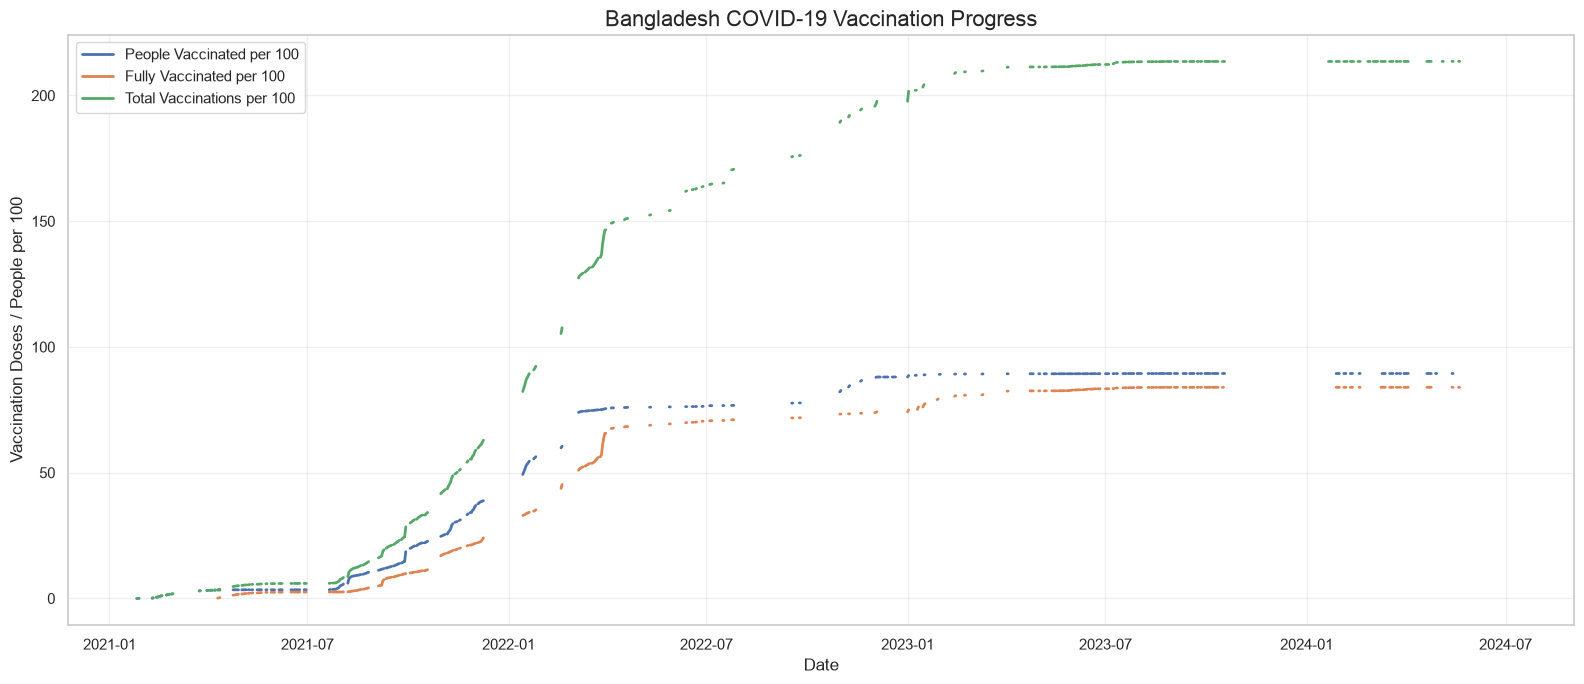

Chart saved: visualizations/bangladesh_vaccination_progress.png


In [94]:
# Create a figure with suitable dimensions
plt.figure(figsize=(16, 7))

# Plot the percentage of people who received at least one dose
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["people_vaccinated_per_hundred"],
    label="People Vaccinated per 100",
    linewidth=2
)

# Plot the percentage of fully vaccinated people
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["people_fully_vaccinated_per_hundred"],
    label="Fully Vaccinated per 100",
    linewidth=2
)

# Plot total vaccine doses administered per 100 people
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["total_vaccinations_per_hundred"],
    label="Total Vaccinations per 100",
    linewidth=2
)

# Add chart title
plt.title(
    "Bangladesh COVID-19 Vaccination Progress",
    fontsize=16
)

# Add axis labels
plt.xlabel("Date", fontsize=12)
plt.ylabel("Vaccination Doses / People per 100", fontsize=12)

# Display the legend
plt.legend()

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("bangladesh_vaccination_progress.png")

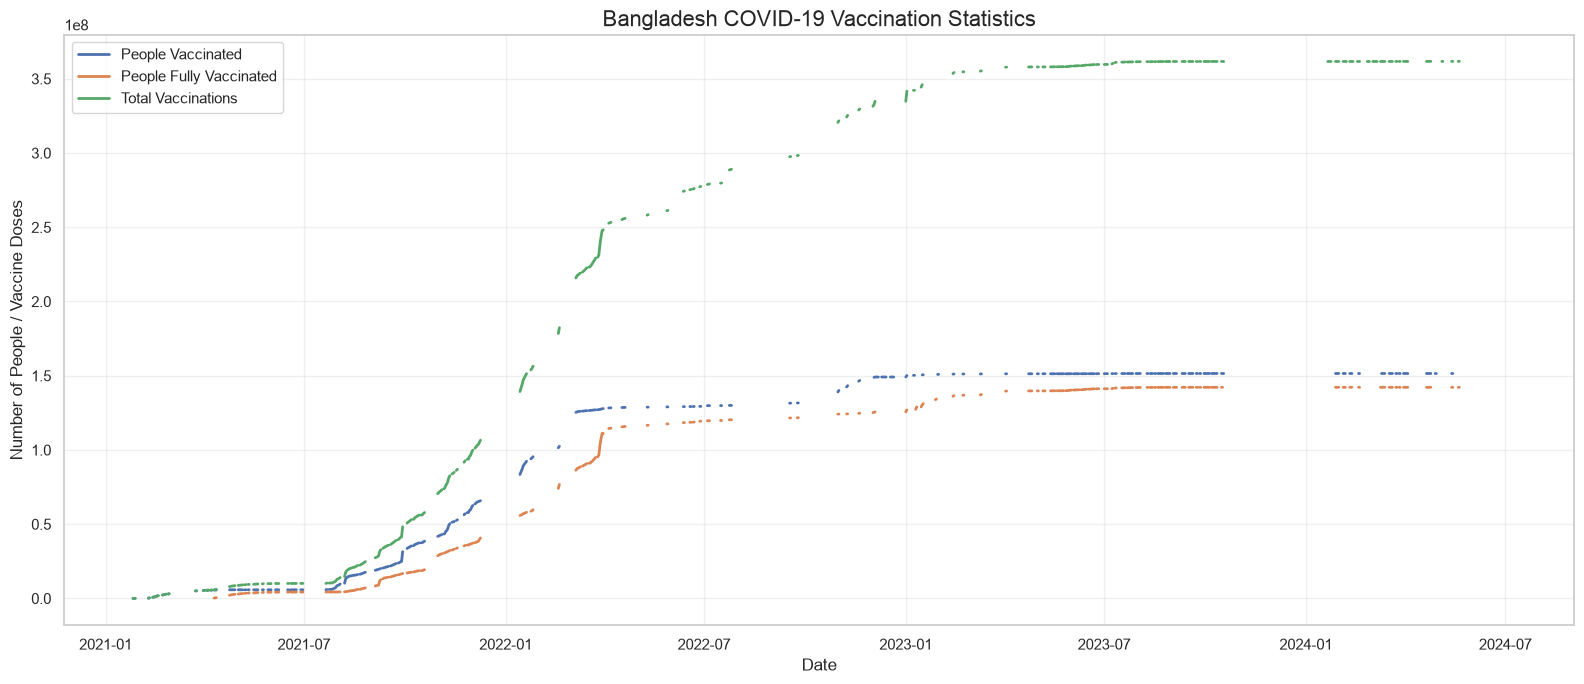

Chart saved: visualizations/bangladesh_vaccination_statistics.png


In [95]:
# Create a figure with suitable dimensions
plt.figure(figsize=(16, 7))

# Plot the total number of people vaccinated
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["people_vaccinated"],
    label="People Vaccinated",
    linewidth=2
)

# Plot the total number of fully vaccinated people
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["people_fully_vaccinated"],
    label="People Fully Vaccinated",
    linewidth=2
)

# Plot the total number of vaccine doses administered
plt.plot(
    bangladesh_vaccination["date"],
    bangladesh_vaccination["total_vaccinations"],
    label="Total Vaccinations",
    linewidth=2
)

# Add chart title
plt.title(
    "Bangladesh COVID-19 Vaccination Statistics",
    fontsize=16
)

# Add axis labels
plt.xlabel("Date", fontsize=12)
plt.ylabel("Number of People / Vaccine Doses", fontsize=12)

# Display the legend
plt.legend()

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("bangladesh_vaccination_statistics.png")

In [96]:
# Export Bangladesh vaccination records to a CSV file
bangladesh_vaccination.to_csv(
    "reports/bangladesh_vaccination_analysis.csv",
    index=False
)

# Confirm successful export
print("Bangladesh vaccination analysis saved successfully.")

Bangladesh vaccination analysis saved successfully.


In [97]:
# Sort country-level records by date
sorted_df = country_level_df.sort_values("date")

# Get the latest available record for each country
latest_country_data = (
    sorted_df
    .groupby("country")
    .tail(1)
    .copy()
)

# Select numerical variables for correlation analysis
correlation_columns = [
    "total_cases",
    "total_deaths",
    "total_tests",
    "total_vaccinations",
    "population",
    "population_density",
    "median_age",
    "gdp_per_capita",
    "diabetes_prevalence",
    "hospital_beds_per_thousand",
    "life_expectancy"
]

# Create a separate DataFrame with selected variables
correlation_df = latest_country_data[
    correlation_columns
].copy()

# Display the first five records
correlation_df.head()

,total_cases,total_deaths,total_tests,total_vaccinations,population,population_density,median_age,gdp_per_capita,diabetes_prevalence,hospital_beds_per_thousand,life_expectancy
612157,NaN,NaN,3943.0,NaN,568746.0,2.138143,31.698000,NaN,NaN,NaN,71.143204
127742,NaN,NaN,NaN,25263932.0,30395004.0,95.581772,17.992001,7014.845703,5.0,NaN,61.562199
325813,NaN,NaN,NaN,NaN,704360.0,21344.242188,37.831001,117098.273438,8.1,NaN,82.102501
561313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
247644,NaN,NaN,NaN,NaN,7465913.0,7110.393555,45.591000,68724.554688,8.2,NaN,83.485298


In [98]:
# Calculate the Pearson correlation matrix
correlation_matrix = correlation_df.corr(
    method="pearson"
)

# Display the correlation matrix
correlation_matrix

,total_cases,total_deaths,total_tests,total_vaccinations,population,population_density,median_age,gdp_per_capita,diabetes_prevalence,hospital_beds_per_thousand,life_expectancy
total_cases,1.000000,0.767034,NaN,NaN,0.694097,-0.023824,0.206591,0.186517,-0.004917,0.201576,0.180708
total_deaths,0.767034,1.000000,NaN,NaN,0.454474,-0.038380,0.122388,0.119336,0.012684,0.037511,0.101246
total_tests,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_vaccinations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population,0.694097,0.454474,NaN,NaN,1.000000,-0.024915,-0.016338,-0.060191,0.032476,0.007271,-0.014295
population_density,-0.023824,-0.038380,NaN,NaN,-0.024915,1.000000,0.187418,0.347738,-0.022399,0.493591,0.199895
median_age,0.206591,0.122388,NaN,NaN,-0.016338,0.187418,1.000000,0.689260,-0.018596,0.652709,0.768310
gdp_per_capita,0.186517,0.119336,NaN,NaN,-0.060191,0.347738,0.689260,1.000000,0.010704,0.372359,0.664377
diabetes_prevalence,-0.004917,0.012684,NaN,NaN,0.032476,-0.022399,-0.018596,0.010704,1.000000,-0.105602,0.156444
hospital_beds_per_thousand,0.201576,0.037511,NaN,NaN,0.007271,0.493591,0.652709,0.372359,-0.105602,1.000000,0.399149


### 7.10 - COVID-19 Correlation Heatmap

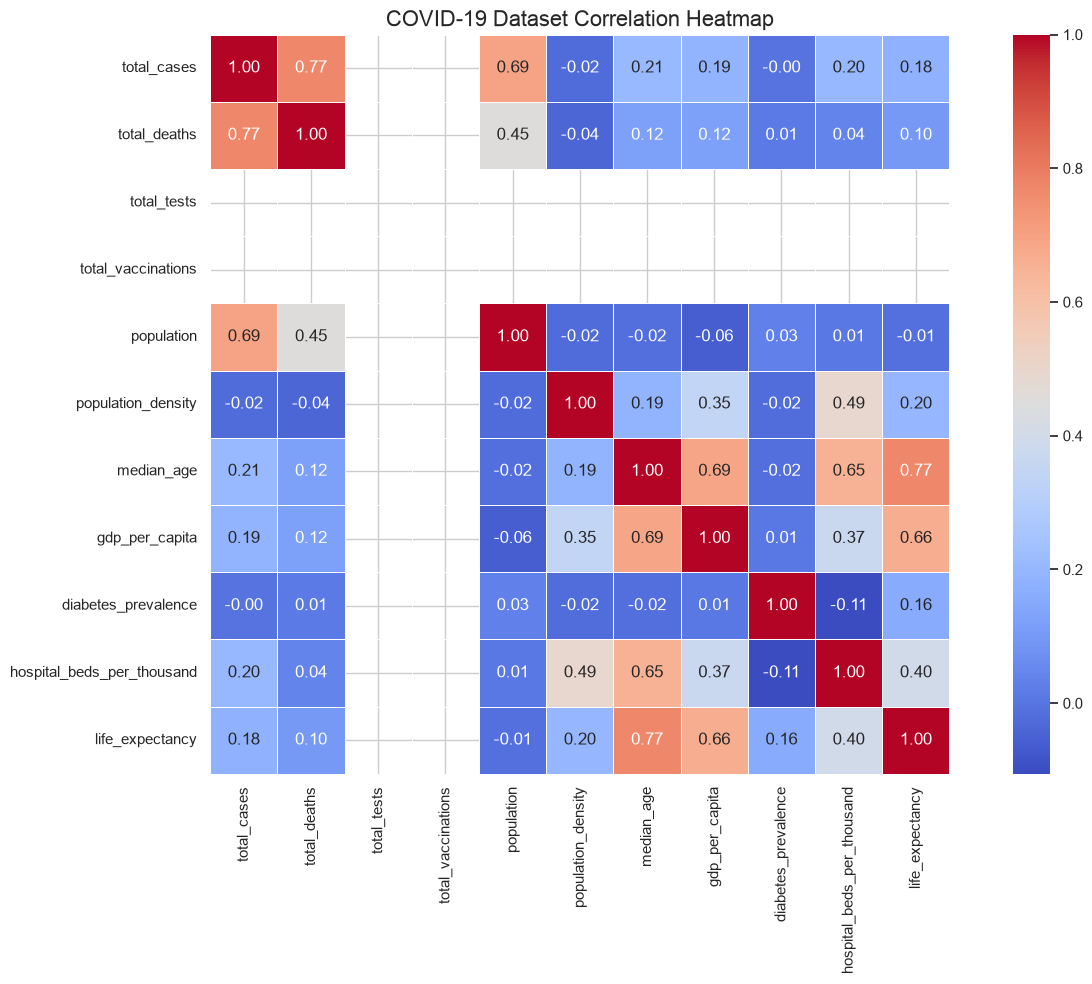

Chart saved: visualizations/covid_correlation_heatmap.png


In [99]:
# Create a figure with suitable dimensions
plt.figure(figsize=(14, 10))

# Create an annotated correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

# Add chart title
plt.title(
    "COVID-19 Dataset Correlation Heatmap",
    fontsize=16
)

# Adjust chart spacing
plt.tight_layout()

# Save and display the heatmap
save_chart("covid_correlation_heatmap.png")

In [100]:
# Export the correlation matrix as a CSV file
correlation_matrix.to_csv(
    "reports/covid_correlation_matrix.csv"
)

# Confirm successful export
print("Correlation matrix saved successfully.")

Correlation matrix saved successfully.


In [101]:
# Select important numerical columns for statistical analysis
stat_columns = [
    "total_cases",
    "new_cases",
    "total_deaths",
    "new_deaths",
    "total_tests",
    "total_vaccinations",
    "population",
    "population_density",
    "total_cases_per_million",
    "total_deaths_per_million"
]

# Create a separate DataFrame containing the selected columns
stat_df = df[stat_columns].copy()

# Display the first five records
stat_df.head()

,total_cases,new_cases,total_deaths,new_deaths,total_tests,total_vaccinations,population,population_density,total_cases_per_million,total_deaths_per_million
0,NaN,NaN,NaN,NaN,NaN,NaN,40578847.0,62.215549,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,40578847.0,62.215549,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,40578847.0,62.215549,NaN,NaN
3,0.0,0.0,0.0,0.0,NaN,NaN,40578847.0,62.215549,0.0,0.0
4,0.0,0.0,0.0,0.0,NaN,NaN,40578847.0,62.215549,0.0,0.0


In [102]:
# Calculate descriptive statistics for all selected variables
descriptive_stats = stat_df.describe().T

# Add the median as a separate column
descriptive_stats["median"] = stat_df.median()

# Add the standard deviation as a separate column
descriptive_stats["std_deviation"] = stat_df.std()

# Display the statistical summary
descriptive_stats

,count,mean,std,min,25%,50%,75%,max,median,std_deviation
total_cases,617520.0,1.538435e+07,7.785043e+07,0.00000,1.161675e+04,9.933300e+04,1.212156e+06,7.794521e+08,9.933300e+04,7.785043e+07
new_cases,612628.0,8.881605e+03,1.077630e+05,0.00000,0.000000e+00,0.000000e+00,2.200000e+01,8.401906e+06,0.000000e+00,1.077630e+05
total_deaths,617520.0,1.632331e+05,8.060507e+05,0.00000,9.200000e+01,1.250000e+03,1.412200e+04,7.117473e+06,1.250000e+03,8.060507e+05
new_deaths,613891.0,8.492375e+01,7.393160e+02,0.00000,0.000000e+00,0.000000e+00,0.000000e+00,5.716700e+04,0.000000e+00,7.393160e+02
total_tests,79387.0,2.110457e+07,8.409869e+07,0.00000,3.646540e+05,2.067330e+06,1.024845e+07,9.214000e+09,2.067330e+06,8.409869e+07
total_vaccinations,83222.0,5.836216e+08,1.881802e+09,0.00000,1.850678e+06,1.572015e+07,1.289842e+08,1.372451e+10,1.572015e+07,1.881802e+09
population,611076.0,1.319342e+08,6.698983e+08,513.00000,4.553740e+05,6.035104e+06,2.971544e+07,8.021407e+09,6.035104e+06,6.698983e+08
population_density,601153.0,3.673912e+02,1.669296e+03,0.13647,3.626586e+01,9.208466e+01,2.374704e+02,2.134424e+04,9.208466e+01,1.669296e+03
total_cases_per_million,617520.0,1.421684e+05,1.815173e+05,0.00000,4.096433e+03,5.983708e+04,2.302997e+05,7.698068e+05,5.983708e+04,1.815173e+05
total_deaths_per_million,617520.0,9.802750e+02,1.211068e+03,0.00000,5.471501e+01,4.567044e+02,1.572429e+03,6.604037e+03,4.567044e+02,1.211068e+03


In [104]:
# Save descriptive statistics as a CSV report
descriptive_stats.to_csv(
    "reports/descriptive_statistics.csv"
)

# Confirm successful export
print("Descriptive statistics report saved successfully.")

Descriptive statistics report saved successfully.


In [105]:
# Sort country-level records by date
sorted_df = country_level_df.sort_values("date")

# Get the latest available record for each country
country_stats = (
    sorted_df
    .groupby("country")
    .tail(1)
    .copy()
)

# Select important country-level indicators
country_stats = country_stats[
    [
        "country",
        "date",
        "population",
        "total_cases",
        "total_deaths",
        "total_cases_per_million",
        "total_deaths_per_million",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred"
    ]
].copy()

# Display the country-level statistics
country_stats.head()

,country,date,population,total_cases,total_deaths,total_cases_per_million,total_deaths_per_million,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
612157,Western Sahara,2022-04-20,568746.0,NaN,NaN,NaN,NaN,NaN,NaN
127742,Cote d'Ivoire,2023-02-19,30395004.0,NaN,NaN,NaN,NaN,44.64014,40.020737
325813,Macao,2023-12-31,704360.0,NaN,NaN,NaN,NaN,NaN,NaN
561313,Transnistria,2023-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
247644,Hong Kong,2024-08-12,7465913.0,NaN,NaN,NaN,NaN,NaN,NaN


In [106]:
# Select cumulative indicators for analysis
country_summary_columns = [
    "total_cases",
    "total_deaths",
    "total_cases_per_million",
    "total_deaths_per_million"
]

# Calculate summary statistics across countries
country_summary = country_stats[
    country_summary_columns
].describe().T

# Add median values
country_summary["median"] = (
    country_stats[country_summary_columns].median()
)

# Display the country-level summary
country_summary

,count,mean,std,min,25%,50%,75%,max,median
total_cases,233.0,3.345288e+06,1.146243e+07,0.0,25292.00000,191496.0000,1.279115e+06,1.034368e+08,191496.0000
total_deaths,233.0,3.054709e+04,1.097336e+05,0.0,172.00000,1937.0000,1.412200e+04,1.240149e+06,1937.0000
total_cases_per_million,233.0,2.084138e+05,2.060282e+05,0.0,20186.77300,135538.2000,3.510868e+05,7.698068e+05,135538.2000
total_deaths_per_million,233.0,1.276173e+03,1.338053e+03,0.0,141.09766,889.3516,2.023351e+03,6.604037e+03,889.3516


In [107]:
# Calculate case fatality rate for each country
# Replace zero case counts with NaN to avoid division by zero
country_stats["case_fatality_rate"] = (
    country_stats["total_deaths"]
    .div(
        country_stats["total_cases"].where(
            country_stats["total_cases"] > 0
        )
    )
    .mul(100)
)

# Display countries with the highest CFR
highest_cfr_countries = country_stats.sort_values(
    by="case_fatality_rate",
    ascending=False
)

# Display the top 10 countries by CFR
highest_cfr_countries[
    ["country", "total_cases", "total_deaths", "case_fatality_rate"]
].head(10)

,country,total_cases,total_deaths,case_fatality_rate
624901,Yemen,11945.0,2159.0,18.074508
534527,Sudan,63993.0,5046.0,7.885237
544984,Syria,57423.0,3163.0,5.508246
517149,Somalia,27334.0,1361.0,4.979147
438885,Peru,4533878.0,221073.0,4.876024
160018,Egypt,516023.0,24830.0,4.811801
355597,Mexico,7632767.0,335205.0,4.391658
74465,Bosnia and Herzegovina,404289.0,16419.0,4.061204
309713,Liberia,7932.0,294.0,3.706505
2482,Afghanistan,235214.0,7998.0,3.400308


### 7.11 - Top 10 Countries by COVID-19 Case Fatality Rate

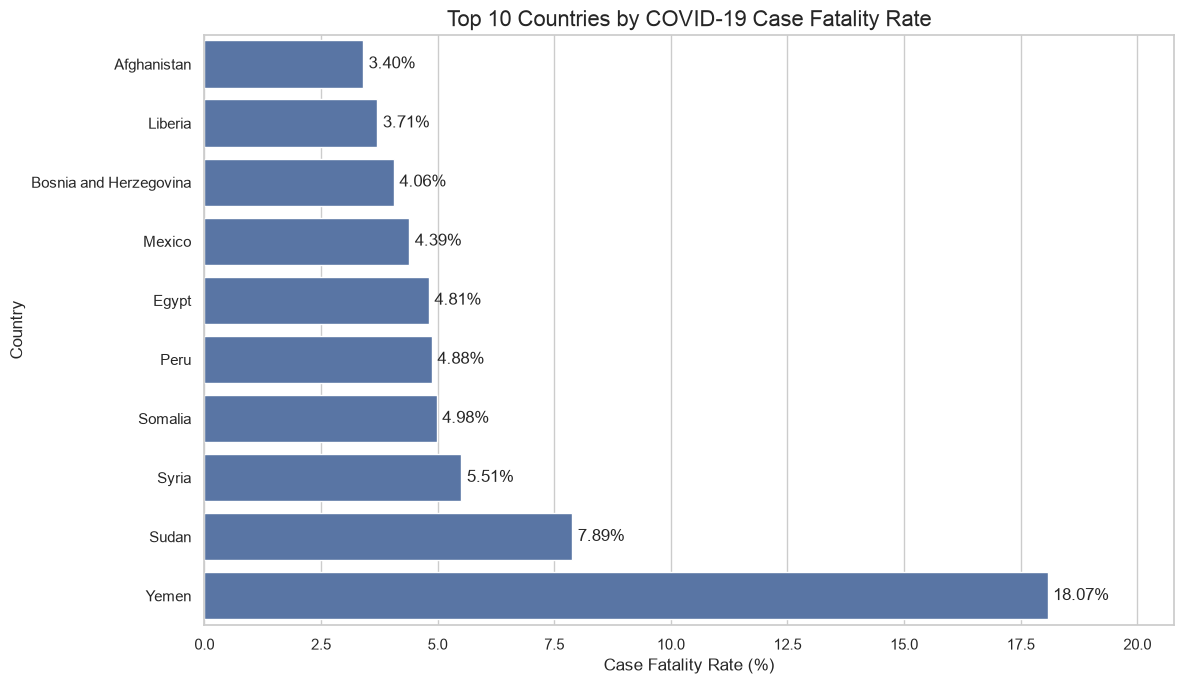

Chart saved: visualizations/top_10_countries_cfr.png


In [108]:
# Select the top 10 countries with available CFR values
top_10_cfr = (
    country_stats
    .dropna(subset=["case_fatality_rate"])
    .sort_values("case_fatality_rate", ascending=False)
    .head(10)
    .sort_values("case_fatality_rate", ascending=True)
)

# Create a figure
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart
ax = sns.barplot(
    data=top_10_cfr,
    x="case_fatality_rate",
    y="country"
)

# Add CFR percentage labels to each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4
    )

# Add chart title and axis labels
plt.title("Top 10 Countries by COVID-19 Case Fatality Rate", fontsize=16)
plt.xlabel("Case Fatality Rate (%)")
plt.ylabel("Country")

# Add extra space for data labels
plt.xlim(0, top_10_cfr["case_fatality_rate"].max() * 1.15)

# Adjust layout
plt.tight_layout()

# Save and display the chart
save_chart("top_10_countries_cfr.png")

In [109]:
# Select countries with available deaths-per-million values
deaths_per_million = country_stats.dropna(
    subset=["total_deaths_per_million"]
).copy()

# Sort countries by reported deaths per million
top_10_deaths_per_million = deaths_per_million.sort_values(
    by="total_deaths_per_million",
    ascending=False
).head(10)

# Display the top 10 countries
top_10_deaths_per_million[
    ["country", "population", "total_deaths_per_million"]
]

,country,population,total_deaths_per_million
438885,Peru,33475436.0,6604.0366
86877,Bulgaria,6825862.0,5681.0405
410196,North Macedonia,1840236.0,5429.1950
74465,Bosnia and Herzegovina,3204802.0,5123.2495
250127,Hungary,9684308.0,5072.5360
130225,Croatia,3907031.0,4813.3735
512183,Slovenia,2115231.0,4686.9585
206262,Georgia,3794782.0,4519.6274
368006,Montenegro,614649.0,4317.9116
140154,Czechia,10673216.0,4122.0005


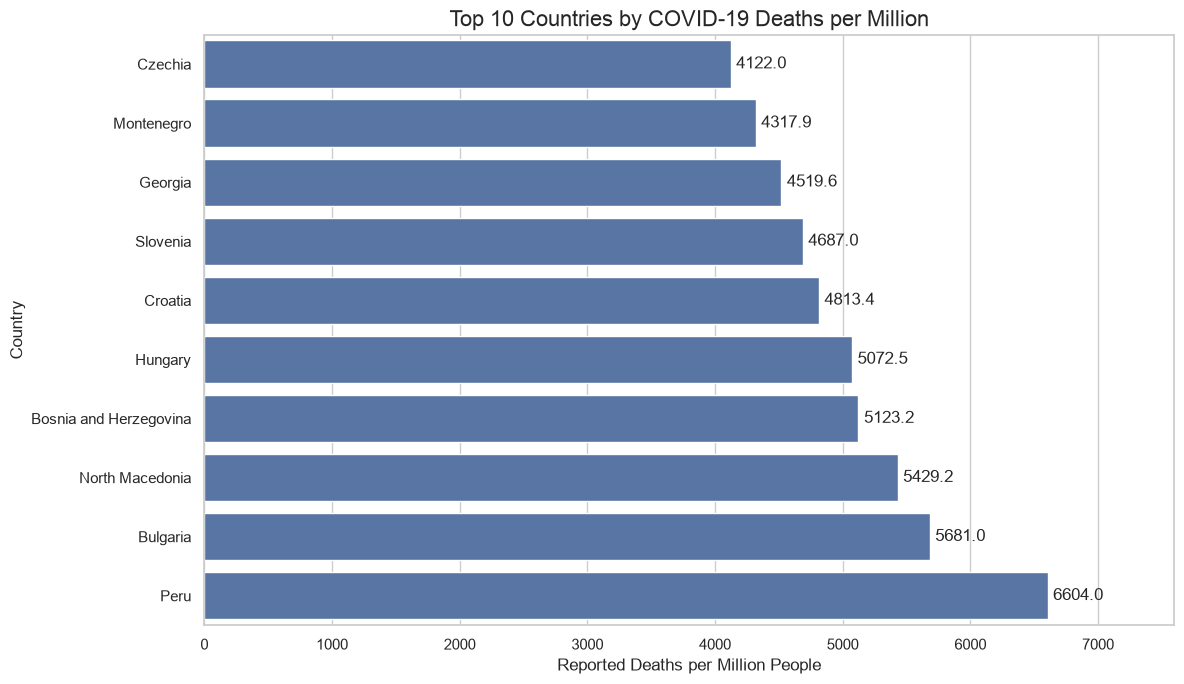

Chart saved: visualizations/top_10_deaths_per_million.png


In [110]:
# Sort the top 10 countries for horizontal plotting
plot_data = top_10_deaths_per_million.sort_values(
    by="total_deaths_per_million",
    ascending=True
)

# Create a figure
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart
ax = sns.barplot(
    data=plot_data,
    x="total_deaths_per_million",
    y="country"
)

# Add values to the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4
    )

# Add chart title and axis labels
plt.title("Top 10 Countries by COVID-19 Deaths per Million", fontsize=16)
plt.xlabel("Reported Deaths per Million People")
plt.ylabel("Country")

# Add extra space for labels
plt.xlim(0, plot_data["total_deaths_per_million"].max() * 1.15)

# Adjust layout
plt.tight_layout()

# Save and display the chart
save_chart("top_10_deaths_per_million.png")

In [113]:
# Sort all country records by country and date
vaccination_source = country_level_df.sort_values(
    ["country", "date"]
).copy()

# Keep only records with available full vaccination coverage
vaccination_source = vaccination_source.dropna(
    subset=["people_fully_vaccinated_per_hundred"]
)

# Get the latest available vaccination record for each country
vaccination_stats = (
    vaccination_source
    .groupby("country")
    .tail(1)
    .copy()
)

# Sort countries by full vaccination coverage
top_vaccinated_countries = (
    vaccination_stats
    .sort_values(
        by="people_fully_vaccinated_per_hundred",
        ascending=False
    )
    .head(10)
)

# Display the top 10 countries with their actual data dates
top_vaccinated_countries[
    [
        "country",
        "date",
        "people_fully_vaccinated_per_hundred"
    ]
]

,country,date,people_fully_vaccinated_per_hundred
212306,Gibraltar,2022-12-16,110.18841
122770,Cook Islands,2023-02-13,99.87116
452520,Qatar,2023-05-07,98.60714
83188,Brunei,2023-06-30,98.09827
381562,Nauru,2023-02-20,95.97361
582073,United Arab Emirates,2022-06-20,95.60813
557369,Tokelau,2022-12-05,95.28547
574850,Tuvalu,2023-02-01,94.93607
503591,Singapore,2023-08-29,92.89906
325804,Macao,2023-04-13,91.18433


In [115]:
# Define the numerical indicators for relationship analysis
relationship_columns = [
    "total_cases",
    "total_deaths",
    "total_tests",
    "total_cases_per_million",
    "total_deaths_per_million",
    "people_fully_vaccinated_per_hundred"
]

# Start with a list of unique countries
relationship_df = (
    country_level_df[["country"]]
    .drop_duplicates()
    .copy()
)

# Retrieve the latest available non-null value for each indicator
for column in relationship_columns:

    # Remove records where the current indicator is missing
    available_data = country_level_df.dropna(
        subset=[column]
    ).copy()

    # Sort records chronologically
    available_data = available_data.sort_values("date")

    # Keep the latest available record for each country
    latest_values = (
        available_data
        .groupby("country")
        .tail(1)[["country", column]]
    )

    # Merge the indicator into the relationship dataset
    relationship_df = relationship_df.merge(
        latest_values,
        on="country",
        how="left"
    )

# Display the prepared relationship dataset
relationship_df.head(10)

,country,total_cases,total_deaths,total_tests,total_cases_per_million,total_deaths_per_million,people_fully_vaccinated_per_hundred
0,Afghanistan,235214.0,7998.0,994894.0,5796.4683,197.09776,45.270844
1,Albania,337234.0,3608.0,1613870.0,119264.5100,1275.98740,45.244260
2,Algeria,272440.0,6881.0,230553.0,5990.6690,151.30595,14.251447
3,American Samoa,8359.0,34.0,NaN,172831.6000,702.98770,NaN
4,Andorra,48015.0,159.0,300307.0,602280.4400,1994.43070,67.109460
5,Angola,107487.0,1937.0,1618566.0,3016.3298,54.35663,26.965265
6,Anguilla,3904.0,12.0,51382.0,274890.8800,844.95140,73.102380
7,Antigua and Barbuda,9106.0,146.0,16700.0,98072.1600,1572.42860,67.187935
8,Argentina,10120270.0,130865.0,36663990.0,222874.6400,2881.98730,76.860214
9,Armenia,454913.0,8785.0,3102267.0,157907.6600,3049.41550,35.779274


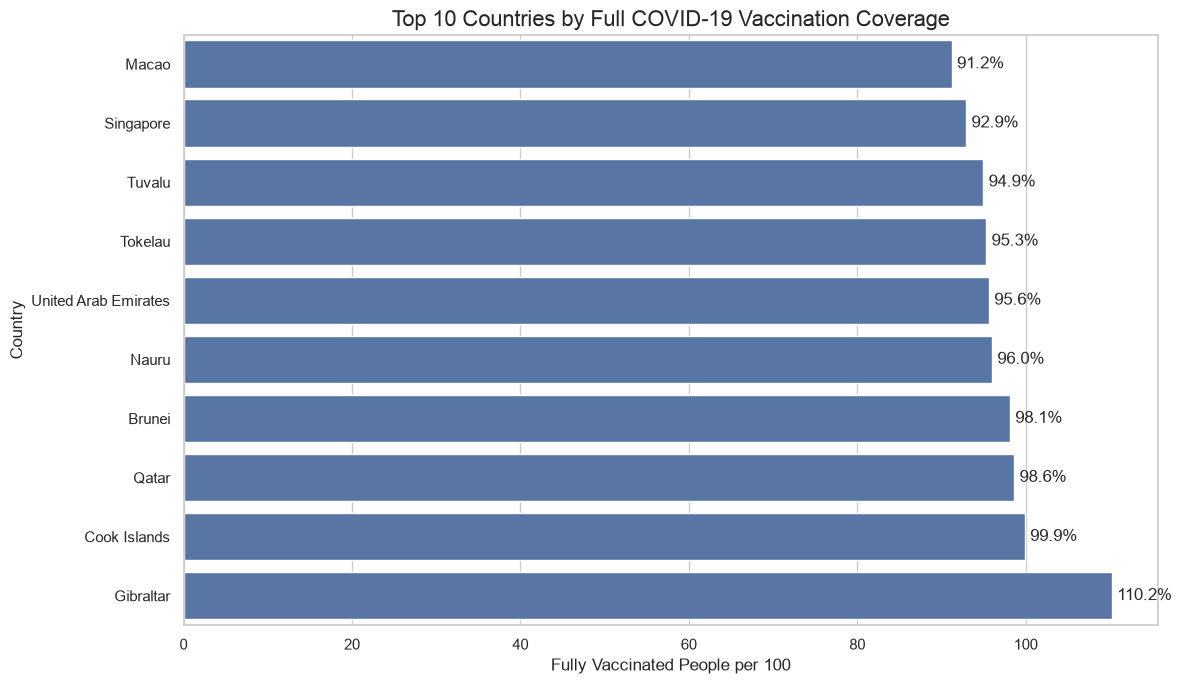

Chart saved: visualizations/top_10_vaccination_coverage.png


In [114]:
# Sort countries in ascending order for horizontal plotting
plot_data = top_vaccinated_countries.sort_values(
    by="people_fully_vaccinated_per_hundred",
    ascending=True
)

# Create a figure
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart
ax = sns.barplot(
    data=plot_data,
    x="people_fully_vaccinated_per_hundred",
    y="country"
)

# Add coverage percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4
    )

# Add chart title and labels
plt.title("Top 10 Countries by Full COVID-19 Vaccination Coverage", fontsize=16)
plt.xlabel("Fully Vaccinated People per 100")
plt.ylabel("Country")

# Adjust chart spacing
plt.tight_layout()

# Save and display the chart
save_chart("top_10_vaccination_coverage.png")

## 8 - Statistical Analysis

In [116]:
# Select numerical indicators for Pearson correlation
pearson_matrix = relationship_df[
    relationship_columns
].corr(method="pearson")

# Display Pearson correlation values
pearson_matrix

,total_cases,total_deaths,total_tests,total_cases_per_million,total_deaths_per_million,people_fully_vaccinated_per_hundred
total_cases,1.000000,0.767034,0.655321,0.097631,0.152283,0.222517
total_deaths,0.767034,1.000000,0.174048,0.010143,0.274224,0.143439
total_tests,0.655321,0.174048,1.000000,-0.020628,-0.040230,0.133250
total_cases_per_million,0.097631,0.010143,-0.020628,1.000000,0.432189,0.488560
total_deaths_per_million,0.152283,0.274224,-0.040230,0.432189,1.000000,0.165615
people_fully_vaccinated_per_hundred,0.222517,0.143439,0.133250,0.488560,0.165615,1.000000


In [117]:
# Calculate Spearman rank correlation
spearman_matrix = relationship_df[
    relationship_columns
].corr(method="spearman")

# Display Spearman correlation values
spearman_matrix

,total_cases,total_deaths,total_tests,total_cases_per_million,total_deaths_per_million,people_fully_vaccinated_per_hundred
total_cases,1.000000,0.942122,0.943378,0.224206,0.507733,0.277002
total_deaths,0.942122,1.000000,0.883614,0.018239,0.480541,0.099772
total_tests,0.943378,0.883614,1.000000,0.340664,0.396952,0.454574
total_cases_per_million,0.224206,0.018239,0.340664,1.000000,0.644266,0.549552
total_deaths_per_million,0.507733,0.480541,0.396952,0.644266,1.000000,0.220493
people_fully_vaccinated_per_hundred,0.277002,0.099772,0.454574,0.549552,0.220493,1.000000


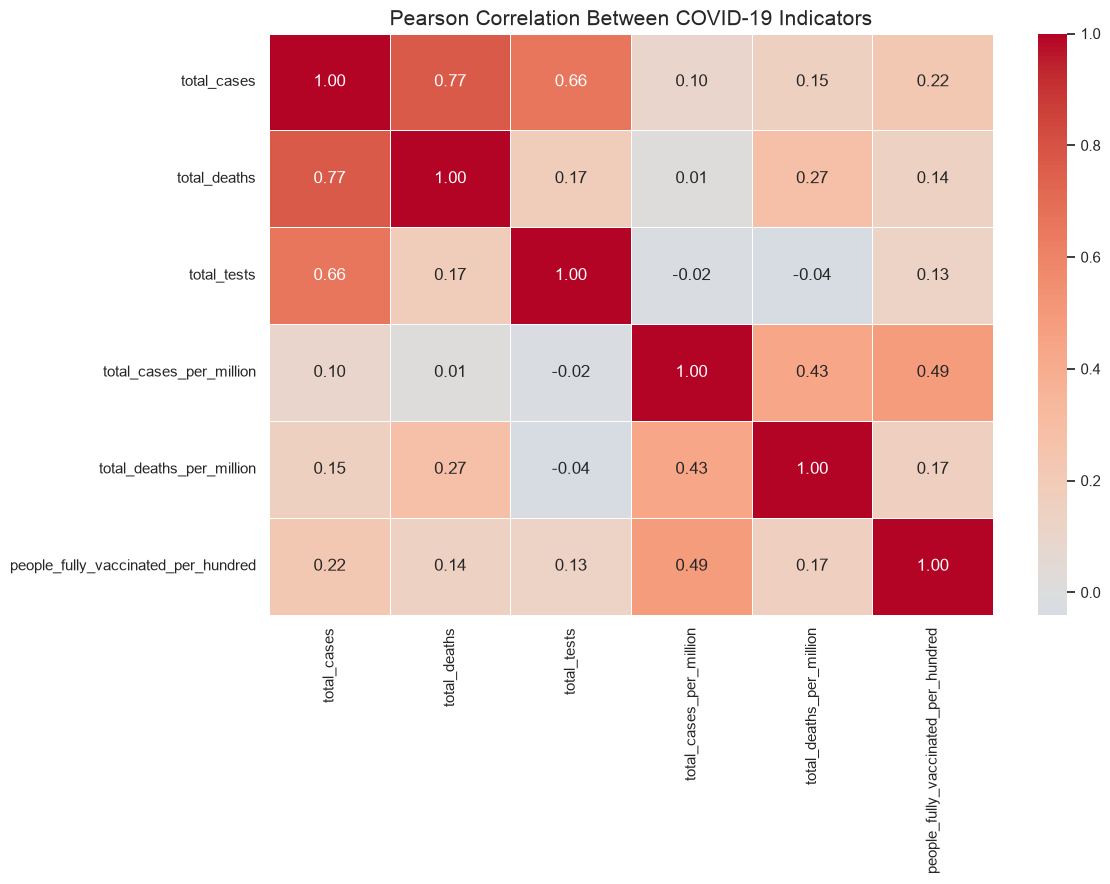

Chart saved: visualizations/pearson_correlation_heatmap.png


In [118]:
# Create a figure for the Pearson correlation heatmap
plt.figure(figsize=(12, 9))

# Draw the annotated Pearson correlation heatmap
sns.heatmap(
    pearson_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

# Add chart title
plt.title(
    "Pearson Correlation Between COVID-19 Indicators",
    fontsize=15
)

# Adjust chart layout
plt.tight_layout()

# Save and display the heatmap
save_chart("pearson_correlation_heatmap.png")

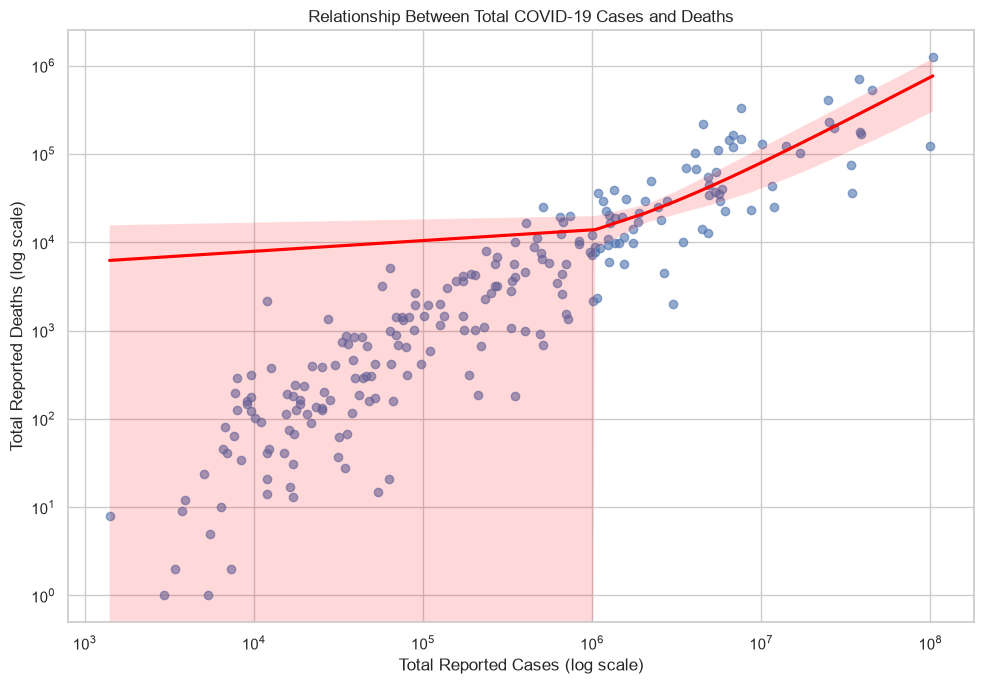

Chart saved: visualizations/cases_vs_deaths_relationship.png


In [119]:
# Keep records with positive total cases and total deaths
cases_deaths_data = relationship_df.dropna(
    subset=["total_cases", "total_deaths"]
).copy()

# Remove zero and negative values before using logarithmic axes
cases_deaths_data = cases_deaths_data[
    (cases_deaths_data["total_cases"] > 0) &
    (cases_deaths_data["total_deaths"] > 0)
]

# Create a scatter plot with a fitted regression line
plt.figure(figsize=(10, 7))

sns.regplot(
    data=cases_deaths_data,
    x="total_cases",
    y="total_deaths",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

# Use logarithmic scales to make the distribution easier to inspect
plt.xscale("log")
plt.yscale("log")

# Add chart title and axis labels
plt.title("Relationship Between Total COVID-19 Cases and Deaths")
plt.xlabel("Total Reported Cases (log scale)")
plt.ylabel("Total Reported Deaths (log scale)")

# Adjust chart layout
plt.tight_layout()

# Save and display the chart
save_chart("cases_vs_deaths_relationship.png")

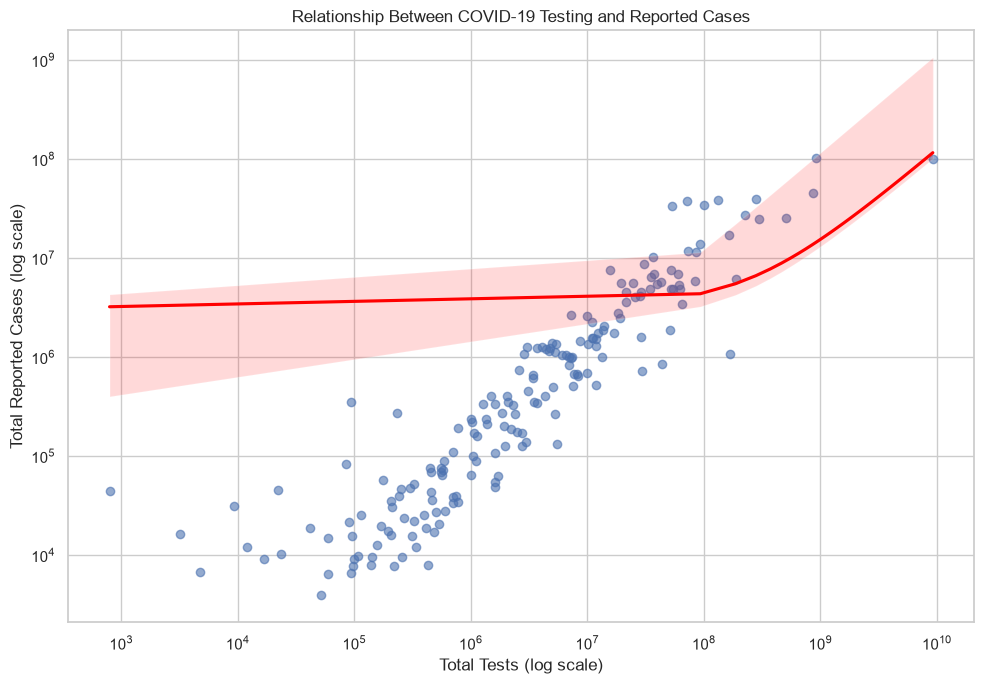

Chart saved: visualizations/testing_vs_cases_relationship.png


In [120]:
# Keep records with positive total tests and total cases
testing_cases_data = relationship_df.dropna(
    subset=["total_tests", "total_cases"]
).copy()

# Remove zero and negative values for logarithmic plotting
testing_cases_data = testing_cases_data[
    (testing_cases_data["total_tests"] > 0) &
    (testing_cases_data["total_cases"] > 0)
]

# Create a scatter plot with a regression line
plt.figure(figsize=(10, 7))

sns.regplot(
    data=testing_cases_data,
    x="total_tests",
    y="total_cases",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

# Apply logarithmic scales
plt.xscale("log")
plt.yscale("log")

# Add chart title and labels
plt.title("Relationship Between COVID-19 Testing and Reported Cases")
plt.xlabel("Total Tests (log scale)")
plt.ylabel("Total Reported Cases (log scale)")

# Adjust chart layout
plt.tight_layout()

# Save and display the chart
save_chart("testing_vs_cases_relationship.png")

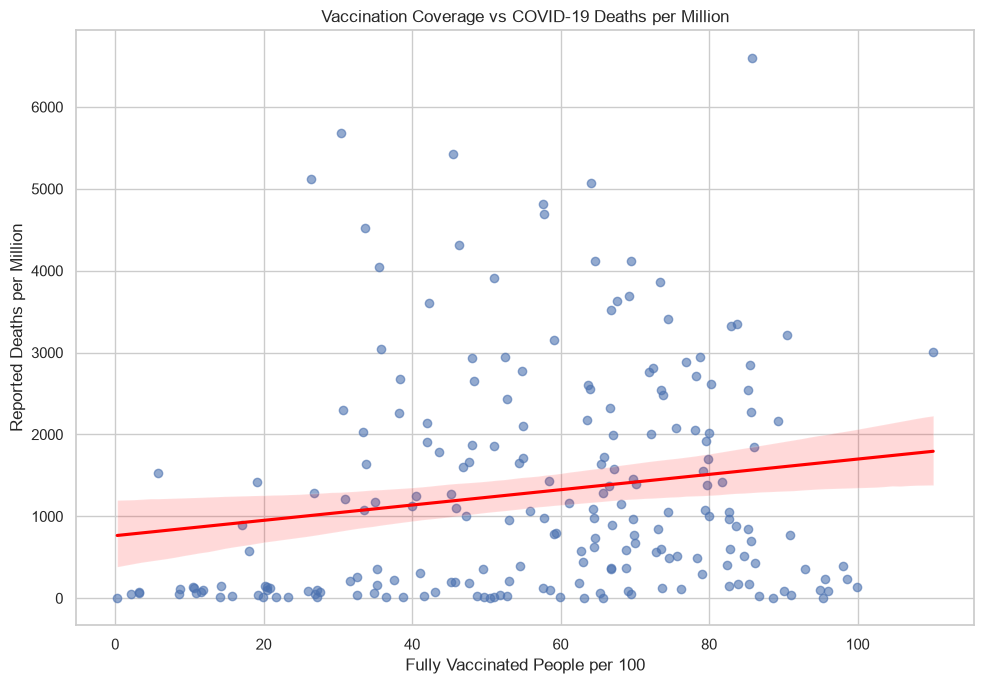

Chart saved: visualizations/vaccination_vs_deaths_relationship.png


In [121]:
# Keep countries with both vaccination coverage and deaths-per-million data
vaccination_deaths_data = relationship_df.dropna(
    subset=[
        "people_fully_vaccinated_per_hundred",
        "total_deaths_per_million"
    ]
).copy()

# Keep non-negative values for this comparison
vaccination_deaths_data = vaccination_deaths_data[
    (vaccination_deaths_data["people_fully_vaccinated_per_hundred"] >= 0) &
    (vaccination_deaths_data["total_deaths_per_million"] >= 0)
]

# Create a scatter plot with a regression line
plt.figure(figsize=(10, 7))

sns.regplot(
    data=vaccination_deaths_data,
    x="people_fully_vaccinated_per_hundred",
    y="total_deaths_per_million",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

# Add chart title and labels
plt.title("Vaccination Coverage vs COVID-19 Deaths per Million")
plt.xlabel("Fully Vaccinated People per 100")
plt.ylabel("Reported Deaths per Million")

# Adjust chart layout
plt.tight_layout()

# Save and display the chart
save_chart("vaccination_vs_deaths_relationship.png")

## 8. Statistical Analysis

In [122]:
# Define the important variable pairs for comparison
important_pairs = [
    ("total_cases", "total_deaths"),
    ("total_tests", "total_cases"),
    ("people_fully_vaccinated_per_hundred", "total_deaths_per_million")
]

# Print Pearson and Spearman correlations for each pair
for first_variable, second_variable in important_pairs:

    # Calculate Pearson correlation for the selected pair
    pearson_value = relationship_df[
        [first_variable, second_variable]
    ].corr(method="pearson").iloc[0, 1]

    # Calculate Spearman correlation for the selected pair
    spearman_value = relationship_df[
        [first_variable, second_variable]
    ].corr(method="spearman").iloc[0, 1]

    # Display the correlation results
    print(f"\n{first_variable} vs {second_variable}")
    print(f"Pearson Correlation: {pearson_value:.3f}")
    print(f"Spearman Correlation: {spearman_value:.3f}")


total_cases vs total_deaths
Pearson Correlation: 0.767
Spearman Correlation: 0.942

total_tests vs total_cases
Pearson Correlation: 0.655
Spearman Correlation: 0.943

people_fully_vaccinated_per_hundred vs total_deaths_per_million
Pearson Correlation: 0.166
Spearman Correlation: 0.220


In [123]:
# Export the Pearson correlation matrix
pearson_matrix.to_csv(
    "reports/pearson_correlation_matrix.csv"
)

# Export the Spearman correlation matrix
spearman_matrix.to_csv(
    "reports/spearman_correlation_matrix.csv"
)

# Export the country-level relationship dataset
relationship_df.to_csv(
    "reports/country_relationship_analysis.csv",
    index=False
)

# Confirm that all reports have been exported
print("Statistical relationship reports saved successfully.")

Statistical relationship reports saved successfully.


In [124]:
# Import the os module for directory and file management
import os

# Create the reports directory if it does not already exist
os.makedirs("reports", exist_ok=True)

# Confirm that the directory is ready
print("Reports directory is ready.")

Reports directory is ready.


In [125]:
# Export the descriptive statistics summary
descriptive_stats.to_csv(
    "reports/descriptive_statistics.csv"
)

# Confirm successful export
print("Descriptive statistics exported.")

Descriptive statistics exported.


In [126]:
# Export country-level COVID-19 statistics
country_stats.to_csv(
    "reports/country_wise_statistics.csv",
    index=False
)

# Confirm successful export
print("Country-wise statistics exported.")

Country-wise statistics exported.


In [127]:
# Select relevant columns for the CFR report
cfr_report = country_stats[
    [
        "country",
        "date",
        "total_cases",
        "total_deaths",
        "case_fatality_rate"
    ]
].copy()

# Sort countries by case fatality rate
cfr_report = cfr_report.sort_values(
    by="case_fatality_rate",
    ascending=False
)

# Export the CFR report
cfr_report.to_csv(
    "reports/case_fatality_rate_analysis.csv",
    index=False
)

# Confirm successful export
print("Case fatality rate report exported.")

Case fatality rate report exported.


In [128]:
# Select relevant columns for deaths-per-million analysis
population_adjusted_report = country_stats[
    [
        "country",
        "date",
        "population",
        "total_deaths",
        "total_deaths_per_million",
        "total_cases_per_million"
    ]
].copy()

# Sort countries by deaths per million
population_adjusted_report = population_adjusted_report.sort_values(
    by="total_deaths_per_million",
    ascending=False
)

# Export the population-adjusted report
population_adjusted_report.to_csv(
    "reports/population_adjusted_analysis.csv",
    index=False
)

# Confirm successful export
print("Population-adjusted report exported.")

Population-adjusted report exported.


In [129]:
# Select relevant vaccination coverage columns
vaccination_report = country_stats[
    [
        "country",
        "date",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred"
    ]
].copy()

# Sort countries by full vaccination coverage
vaccination_report = vaccination_report.sort_values(
    by="people_fully_vaccinated_per_hundred",
    ascending=False
)

# Export the vaccination coverage report
vaccination_report.to_csv(
    "reports/vaccination_coverage_analysis.csv",
    index=False
)

# Confirm successful export
print("Vaccination coverage report exported.")

Vaccination coverage report exported.


In [130]:
# Export the Pearson correlation matrix
pearson_matrix.to_csv(
    "reports/pearson_correlation_matrix.csv"
)

# Export the Spearman correlation matrix
spearman_matrix.to_csv(
    "reports/spearman_correlation_matrix.csv"
)

# Export the country-level relationship dataset
relationship_df.to_csv(
    "reports/country_relationship_analysis.csv",
    index=False
)

# Confirm successful export
print("Correlation analysis reports exported.")

Correlation analysis reports exported.


In [131]:
# Create a dictionary containing key statistical indicators
statistical_summary = {
    "Metric": [
        "Total Countries Analyzed",
        "Average Country Total Cases",
        "Median Country Total Cases",
        "Average Country Total Deaths",
        "Median Country Total Deaths",
        "Average Case Fatality Rate",
        "Average Deaths per Million",
        "Average Full Vaccination Coverage"
    ],

    "Value": [
        country_stats["country"].nunique(),
        country_stats["total_cases"].mean(),
        country_stats["total_cases"].median(),
        country_stats["total_deaths"].mean(),
        country_stats["total_deaths"].median(),
        country_stats["case_fatality_rate"].mean(),
        country_stats["total_deaths_per_million"].mean(),
        country_stats["people_fully_vaccinated_per_hundred"].mean()
    ]
}

# Convert the summary dictionary into a DataFrame
final_statistical_summary = pd.DataFrame(statistical_summary)

# Export the final statistical summary
final_statistical_summary.to_csv(
    "reports/final_statistical_summary.csv",
    index=False
)

# Display the summary
final_statistical_summary

,Metric,Value
0,Total Countries Analyzed,2.390000e+02
1,Average Country Total Cases,3.345288e+06
2,Median Country Total Cases,1.914960e+05
3,Average Country Total Deaths,3.054709e+04
4,Median Country Total Deaths,1.937000e+03
5,Average Case Fatality Rate,1.232877e+00
6,Average Deaths per Million,1.276173e+03
7,Average Full Vaccination Coverage,4.002074e+01


In [141]:
# List all files available in the reports directory
report_files = os.listdir("reports")

# Display the exported report filenames
print("Generated Statistical Reports:\n")

for file_name in sorted(report_files):

    # Display each report filename
    print(file_name)

# Display the total number of exported files
print("\nTotal Report Files:", len(report_files))

Generated Statistical Reports:

bangladesh_cases_analysis.csv
bangladesh_monthly_cases.csv
bangladesh_vaccination_analysis.csv
case_fatality_rate_analysis.csv
country_relationship_analysis.csv
country_wise_statistics.csv
covid_correlation_matrix.csv
descriptive_statistics.csv
final_statistical_summary.csv
pearson_correlation_matrix.csv
population_adjusted_analysis.csv
spearman_correlation_matrix.csv
top_10_countries_cases.csv
top_10_countries_deaths.csv
vaccination_coverage_analysis.csv

Total Report Files: 15


## 9 - Key Findings & Insights

In [142]:
# Create a dictionary to store global COVID-19 findings
global_findings = {}

# Find the date with the highest reported daily cases
cases_peak_index = global_daily_cases["new_cases"].idxmax()

# Retrieve the record for the highest daily cases
cases_peak_record = global_daily_cases.loc[cases_peak_index]

# Store the peak daily cases information
global_findings["Peak Daily Cases Date"] = cases_peak_record["date"]
global_findings["Peak Daily Cases"] = cases_peak_record["new_cases"]

# Find the date with the highest reported daily deaths
deaths_peak_index = global_daily_deaths["new_deaths"].idxmax()

# Retrieve the record for the highest daily deaths
deaths_peak_record = global_daily_deaths.loc[deaths_peak_index]

# Store the peak daily deaths information
global_findings["Peak Daily Deaths Date"] = deaths_peak_record["date"]
global_findings["Peak Daily Deaths"] = deaths_peak_record["new_deaths"]

# Find the date with the highest 7-day average of reported deaths
deaths_average_index = global_daily_deaths["7_day_average"].idxmax()

# Retrieve the corresponding rolling-average record
deaths_average_record = global_daily_deaths.loc[deaths_average_index]

# Store the peak 7-day average information
global_findings["Peak 7-Day Average Deaths Date"] = deaths_average_record["date"]
global_findings["Peak 7-Day Average Deaths"] = deaths_average_record["7_day_average"]

# Convert the findings dictionary into a DataFrame
global_findings_df = pd.DataFrame(
    list(global_findings.items()),
    columns=["Metric", "Value"]
)

# Display the global findings
global_findings_df

,Metric,Value
0,Peak Daily Cases Date,2022-01-30 00:00:00
1,Peak Daily Cases,8401906.0
2,Peak Daily Deaths Date,2023-02-01 00:00:00
3,Peak Daily Deaths,57167.0
4,Peak 7-Day Average Deaths Date,2021-01-28 00:00:00
5,Peak 7-Day Average Deaths,14820.714286


In [143]:
# Select the top 10 countries by cumulative reported cases
top_cases_findings = (
    country_stats
    .dropna(subset=["total_cases"])
    .nlargest(10, "total_cases")
    [["country", "date", "total_cases"]]
    .copy()
)

# Select the top 10 countries by cumulative reported deaths
top_deaths_findings = (
    country_stats
    .dropna(subset=["total_deaths"])
    .nlargest(10, "total_deaths")
    [["country", "date", "total_deaths"]]
    .copy()
)

# Display both country rankings
print("Top 10 Countries by Total Cases")
display(top_cases_findings)

print("Top 10 Countries by Total Deaths")
display(top_deaths_findings)

Top 10 Countries by Total Cases


,country,date,total_cases
588620,United States,2026-10-18,103436829.0
114187,China,2026-10-18,99381761.0
255093,India,2026-10-18,45056221.0
193853,France,2026-10-18,39064913.0
208745,Germany,2026-10-18,38437953.0
79431,Brazil,2026-10-18,38058695.0
524595,South Korea,2026-10-18,34571873.0
277437,Japan,2026-10-18,33803572.0
272471,Italy,2026-10-18,26969918.0
586137,United Kingdom,2026-10-18,25143403.0


Top 10 Countries by Total Deaths


,country,date,total_deaths
588620,United States,2026-10-18,1240149.0
79431,Brazil,2026-10-18,704109.0
255093,India,2026-10-18,533849.0
461226,Russia,2026-10-18,404290.0
355597,Mexico,2026-10-18,335205.0
586137,United Kingdom,2026-10-18,232612.0
438885,Peru,2026-10-18,221073.0
272471,Italy,2026-10-18,198523.0
208745,Germany,2026-10-18,174979.0
193853,France,2026-10-18,168207.0


In [144]:
# Calculate the total reported cases and deaths in Bangladesh
bangladesh_total_cases = bangladesh_df["total_cases"].max()
bangladesh_total_deaths = bangladesh_df["total_deaths"].max()

# Find the date with the highest daily reported cases
bangladesh_peak_cases_index = bangladesh_df["new_cases"].idxmax()

# Retrieve the peak daily cases record
bangladesh_peak_cases = bangladesh_df.loc[
    bangladesh_peak_cases_index
]

# Find the date with the highest daily reported deaths
bangladesh_peak_deaths_index = bangladesh_df["new_deaths"].idxmax()

# Retrieve the peak daily deaths record
bangladesh_peak_deaths = bangladesh_df.loc[
    bangladesh_peak_deaths_index
]

# Display Bangladesh findings
print("Bangladesh Total Reported Cases:", bangladesh_total_cases)
print("Bangladesh Total Reported Deaths:", bangladesh_total_deaths)

print("\nPeak Daily Cases Date:", bangladesh_peak_cases["date"])
print("Peak Daily Cases:", bangladesh_peak_cases["new_cases"])

print("\nPeak Daily Deaths Date:", bangladesh_peak_deaths["date"])
print("Peak Daily Deaths:", bangladesh_peak_deaths["new_deaths"])

Bangladesh Total Reported Cases: 2052280.0
Bangladesh Total Reported Deaths: 29531.0

Peak Daily Cases Date: 2021-07-28 00:00:00
Peak Daily Cases: 16230.0

Peak Daily Deaths Date: 2021-08-05 00:00:00
Peak Daily Deaths: 264.0


In [145]:
# Find the latest available record for people vaccinated
latest_people_vaccinated = (
    bangladesh_df
    .dropna(subset=["people_vaccinated"])
    .sort_values("date")
    .tail(1)
)

# Find the latest available record for fully vaccinated people
latest_fully_vaccinated = (
    bangladesh_df
    .dropna(subset=["people_fully_vaccinated"])
    .sort_values("date")
    .tail(1)
)

# Find the latest available record for vaccination coverage
latest_vaccination_coverage = (
    bangladesh_df
    .dropna(subset=["people_fully_vaccinated_per_hundred"])
    .sort_values("date")
    .tail(1)
)

# Display the latest available vaccination information
print("Latest People Vaccinated:")
display(
    latest_people_vaccinated[
        ["date", "people_vaccinated"]
    ]
)

print("Latest Fully Vaccinated People:")
display(
    latest_fully_vaccinated[
        ["date", "people_fully_vaccinated"]
    ]
)

print("Latest Full Vaccination Coverage:")
display(
    latest_vaccination_coverage[
        ["date", "people_fully_vaccinated_per_hundred"]
    ]
)

Latest People Vaccinated:


,date,people_vaccinated
48790,2024-06-22,151507170.0


Latest Fully Vaccinated People:


,date,people_fully_vaccinated
48799,2024-07-01,142201680.0


Latest Full Vaccination Coverage:


,date,people_fully_vaccinated_per_hundred
48799,2024-07-01,83.95181


In [146]:
# Keep countries with valid case fatality rate values
valid_cfr = country_stats.dropna(
    subset=["case_fatality_rate", "total_cases"]
).copy()

# Find the country with the highest reported CFR
highest_cfr = valid_cfr.loc[
    valid_cfr["case_fatality_rate"].idxmax()
]

# Find the country with the lowest reported CFR
lowest_cfr = valid_cfr.loc[
    valid_cfr["case_fatality_rate"].idxmin()
]

# Display the highest CFR finding
print("Highest CFR Country:", highest_cfr["country"])
print("Highest CFR:", highest_cfr["case_fatality_rate"])

# Display the lowest CFR finding
print("\nLowest CFR Country:", lowest_cfr["country"])
print("Lowest CFR:", lowest_cfr["case_fatality_rate"])

Highest CFR Country: Yemen
Highest CFR: 18.07450816241105

Lowest CFR Country: Tokelau
Lowest CFR: 0.0


In [147]:
# Define the important variable pairs
correlation_pairs = [
    ("total_cases", "total_deaths"),
    ("total_tests", "total_cases"),
    ("people_fully_vaccinated_per_hundred", "total_deaths_per_million")
]

# Store the correlation results
correlation_findings = []

# Calculate Pearson and Spearman values for each pair
for first_variable, second_variable in correlation_pairs:

    # Calculate Pearson correlation
    pearson_value = relationship_df[
        [first_variable, second_variable]
    ].corr(method="pearson").iloc[0, 1]

    # Calculate Spearman correlation
    spearman_value = relationship_df[
        [first_variable, second_variable]
    ].corr(method="spearman").iloc[0, 1]

    # Append the results to the findings list
    correlation_findings.append({
        "Variable 1": first_variable,
        "Variable 2": second_variable,
        "Pearson Correlation": pearson_value,
        "Spearman Correlation": spearman_value
    })

# Convert the results into a DataFrame
correlation_findings_df = pd.DataFrame(correlation_findings)

# Display the correlation findings
correlation_findings_df

,Variable 1,Variable 2,Pearson Correlation,Spearman Correlation
0,total_cases,total_deaths,0.767034,0.942122
1,total_tests,total_cases,0.655321,0.943378
2,people_fully_vaccinated_per_hundred,total_deaths_per_million,0.165615,0.220493


In [148]:
# Create the reports directory if it does not exist
os.makedirs("reports", exist_ok=True)

# Export global COVID-19 findings
global_findings_df.to_csv(
    "reports/global_covid_findings.csv",
    index=False
)

# Export top 10 countries by cases
top_cases_findings.to_csv(
    "reports/top_10_cases_findings.csv",
    index=False
)

# Export top 10 countries by deaths
top_deaths_findings.to_csv(
    "reports/top_10_deaths_findings.csv",
    index=False
)

# Export important correlation findings
correlation_findings_df.to_csv(
    "reports/correlation_findings.csv",
    index=False
)

# Export Bangladesh vaccination findings
bangladesh_vaccination_findings = pd.DataFrame([
    {
        "Metric": "People Vaccinated",
        "Date": latest_people_vaccinated["date"].iloc[0],
        "Value": latest_people_vaccinated["people_vaccinated"].iloc[0]
    },
    {
        "Metric": "People Fully Vaccinated",
        "Date": latest_fully_vaccinated["date"].iloc[0],
        "Value": latest_fully_vaccinated["people_fully_vaccinated"].iloc[0]
    },
    {
        "Metric": "Fully Vaccinated per 100",
        "Date": latest_vaccination_coverage["date"].iloc[0],
        "Value": latest_vaccination_coverage[
            "people_fully_vaccinated_per_hundred"
        ].iloc[0]
    }
])

# Save Bangladesh vaccination findings
bangladesh_vaccination_findings.to_csv(
    "reports/bangladesh_vaccination_findings.csv",
    index=False
)

# Export CFR findings
pd.DataFrame([
    {
        "Metric": "Highest CFR",
        "Country": highest_cfr["country"],
        "Value": highest_cfr["case_fatality_rate"]
    },
    {
        "Metric": "Lowest CFR",
        "Country": lowest_cfr["country"],
        "Value": lowest_cfr["case_fatality_rate"]
    }
]).to_csv(
    "../reports/cfr_findings.csv",
    index=False
)

# Confirm successful export
print("All key findings reports exported successfully.")

All key findings reports exported successfully.


In [149]:
# Display the global findings
print("=" * 55)
print("GLOBAL COVID-19 FINDINGS")
print("=" * 55)

# Print each global finding
for metric, value in global_findings.items():
    print(f"{metric}: {value}")

# Display the most affected country by reported cases
print("\n" + "=" * 55)
print("MOST AFFECTED COUNTRIES")
print("=" * 55)

print(
    "Highest reported cases:",
    top_cases_findings.iloc[0]["country"]
)

print(
    "Highest reported deaths:",
    top_deaths_findings.iloc[0]["country"]
)

# Display Bangladesh findings
print("\n" + "=" * 55)
print("BANGLADESH FINDINGS")
print("=" * 55)

print("Total reported cases:", bangladesh_total_cases)
print("Total reported deaths:", bangladesh_total_deaths)

print(
    "Peak daily cases:",
    bangladesh_peak_cases["new_cases"],
    "on",
    bangladesh_peak_cases["date"]
)

print(
    "Peak daily deaths:",
    bangladesh_peak_deaths["new_deaths"],
    "on",
    bangladesh_peak_deaths["date"]
)

# Display the correlation results
print("\n" + "=" * 55)
print("CORRELATION FINDINGS")
print("=" * 55)

display(correlation_findings_df)

GLOBAL COVID-19 FINDINGS
Peak Daily Cases Date: 2022-01-30 00:00:00
Peak Daily Cases: 8401906.0
Peak Daily Deaths Date: 2023-02-01 00:00:00
Peak Daily Deaths: 57167.0
Peak 7-Day Average Deaths Date: 2021-01-28 00:00:00
Peak 7-Day Average Deaths: 14820.714285714286

MOST AFFECTED COUNTRIES
Highest reported cases: United States
Highest reported deaths: United States

BANGLADESH FINDINGS
Total reported cases: 2052280.0
Total reported deaths: 29531.0
Peak daily cases: 16230.0 on 2021-07-28 00:00:00
Peak daily deaths: 264.0 on 2021-08-05 00:00:00

CORRELATION FINDINGS


,Variable 1,Variable 2,Pearson Correlation,Spearman Correlation
0,total_cases,total_deaths,0.767034,0.942122
1,total_tests,total_cases,0.655321,0.943378
2,people_fully_vaccinated_per_hundred,total_deaths_per_million,0.165615,0.220493


## 10 - Final Report

In [202]:

# ============================================================
# COVID-19 DATA ANALYSIS PROJECT
# FINAL PROJECT REPORT GENERATION
# ============================================================

# Import required libraries
import os
import pandas as pd
from pathlib import Path
import markdown


# ============================================================
# 1. CREATE PROJECT DIRECTORIES
# ============================================================

# Define project directories
reports_dir = Path("reports")
visualization_dir = Path("visualizations")

# Create reports directory if it does not exist
reports_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. PREPARE DATASET INFORMATION
# ============================================================

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Calculate basic dataset information
total_rows = len(df)
total_columns = len(df.columns)
total_countries = df["country"].nunique()

# Get dataset date range
start_date = df["date"].min().strftime("%Y-%m-%d")
end_date = df["date"].max().strftime("%Y-%m-%d")


# ============================================================
# 3. FIND ALL VISUALIZATION IMAGES
# ============================================================

# Find all PNG images inside visualization directory
image_files = sorted(visualization_dir.glob("*.png"))

# Generate Markdown image sections automatically
visualization_section = ""

for image_path in image_files:

    # Convert filename into a readable chart title
    image_title = image_path.stem.replace("_", " ").title()

    # Create relative image path from reports directory
    relative_image_path = f"../visualizations/{image_path.name}"

    # Add chart title and image to report
    visualization_section += (
        f"\n### {image_title}\n\n"
        f"![{image_title}]({relative_image_path})\n\n"
    )

# Handle case when no images are found
if not image_files:
    visualization_section = (
        "\nNo visualization images were found in the visualizations directory.\n"
    )


# ============================================================
# 4. GENERATE FINAL MARKDOWN REPORT
# ============================================================

report_content = f"""
# COVID-19 Data Analysis Project

## 1. Project Overview

This project analyzes global COVID-19 data using Python.
It explores reported cases, deaths, testing, vaccination progress,
and country-level differences through data analysis and visualization.

The project also focuses on Bangladesh to examine its COVID-19
case trends, death trends, and vaccination progress.

## 2. Project Objectives

- Analyze global COVID-19 cases and deaths over time.
- Identify countries with high reported case and death counts.
- Explore Bangladesh's COVID-19 situation.
- Analyze vaccination progress in Bangladesh and other countries.
- Calculate and compare Case Fatality Rates (CFR).
- Examine relationships between selected COVID-19 indicators.
- Present findings through statistical summaries and visualizations.

## 3. Dataset Description

The dataset was obtained from the Our World in Data COVID-19
compact dataset.

| Dataset Information | Value |
|---|---|
| Total records after preprocessing | {total_rows:,} |
| Total columns after preprocessing | {total_columns:,} |
| Unique countries/entities | {total_countries:,} |
| First available date | {start_date} |
| Last available date | {end_date} |

The dataset includes information about reported COVID-19 cases,
deaths, testing, hospitalizations, vaccinations, population,
and selected demographic indicators.

## 4. Tools and Technologies

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 5. Data Preprocessing

The preprocessing workflow included:

- Loading the COVID-19 CSV dataset.
- Inspecting dataset dimensions, data types, and missing values.
- Removing completely empty columns.
- Checking missing country and date values.
- Inspecting duplicate country-date records.
- Sorting records chronologically.
- Reviewing negative daily case and death values.
- Creating derived date and statistical features.

Missing values were not universally replaced with zero because
a missing observation does not necessarily mean zero reported cases.

## 6. Exploratory Data Analysis

The exploratory analysis examined:

- Dataset structure and descriptive statistics.
- Country-level cumulative cases and deaths.
- Global daily and monthly case trends.
- Global daily death trends.
- Bangladesh's daily and monthly case trends.
- Bangladesh's reported death trends.
- Bangladesh's vaccination progress.
- Relationships between selected numerical indicators.

## 7. Feature Engineering

The analysis included derived indicators such as:

- Case Fatality Rate (CFR).
- Year, month number, and month name.
- Cases excluding reported deaths.

Cases excluding reported deaths should not be interpreted as
actual active cases or recovered cases.

## 8. Statistical Analysis

The statistical analysis included:

- Mean, median, standard deviation, minimum, and maximum.
- Country-level cumulative case and death comparisons.
- Case Fatality Rate calculations.
- Cases and deaths per million people.
- Full vaccination coverage comparisons.
- Pearson correlation analysis.
- Spearman rank correlation analysis.

## 9. Key Findings

The project findings are generated from the processed dataset
and are documented in the accompanying CSV reports.

See the following files in the reports directory:

- global_covid_findings.csv
- top_10_cases_findings.csv
- top_10_deaths_findings.csv
- correlation_findings.csv
- bangladesh_vaccination_findings.csv
- cfr_findings.csv

## 10. Visualizations

The following charts illustrate the major trends and comparisons
identified during the COVID-19 data analysis.

{visualization_section}

## 11. Limitations

- Reported cases and deaths depend on testing and reporting practices.
- Missing values can affect country-level comparisons.
- Countries may have different latest available observation dates.
- Cumulative totals should not be interpreted as daily counts.
- Negative daily values may reflect retrospective reporting corrections.
- Correlation does not establish causation.
- Country-level vaccination and death comparisons do not prove vaccine effectiveness.
- Per-million indicators help account for population size but do not remove
  differences in demographics, healthcare systems, or reporting quality.

## 12. Conclusion

This project demonstrates how Python data analysis tools can be used
to process, explore, visualize, and statistically analyze a large
real-world public health dataset.

The analysis provides an overview of global COVID-19 trends and
a focused examination of Bangladesh. It also demonstrates the
importance of data quality, appropriate statistical interpretation,
and clear visual communication.

---

**Project:** COVID-19 Data Analysis  
**Dataset:** Our World in Data COVID-19 Compact Dataset  
**Environment:** Python and Jupyter Notebook
"""


# ============================================================
# 5. SAVE MARKDOWN REPORT
# ============================================================

# Define Markdown report path
markdown_path = reports_dir / "final_project_report.md"

# Save Markdown report
markdown_path.write_text(report_content, encoding="utf-8")

print("Markdown report created successfully!")


# ============================================================
# 6. CONVERT MARKDOWN REPORT INTO HTML
# ============================================================

# Convert Markdown content into HTML
html_body = markdown.markdown(
    report_content,
    extensions=["tables", "fenced_code"]
)

# Create a complete HTML document with CSS styling
html_content = f"""
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">

    <meta name="viewport" content="width=device-width, initial-scale=1.0">

    <title>COVID-19 Data Analysis Report</title>

    <style>

        body {{
            font-family: Arial, sans-serif;
            line-height: 1.7;
            max-width: 1100px;
            margin: 40px auto;
            padding: 20px;
            color: #333;
            background-color: #f5f7fa;
        }}

        .container {{
            background-color: white;
            padding: 40px;
            border-radius: 10px;
            box-shadow: 0 2px 12px rgba(0,0,0,0.08);
        }}

        h1, h2, h3 {{
            color: #183b66;
        }}

        h1 {{
            text-align: center;
            border-bottom: 3px solid #183b66;
            padding-bottom: 15px;
        }}

        h2 {{
            margin-top: 35px;
            border-bottom: 1px solid #ddd;
            padding-bottom: 8px;
        }}

        table {{
            width: 100%;
            border-collapse: collapse;
            margin: 20px 0;
        }}

        th, td {{
            border: 1px solid #ddd;
            padding: 12px;
            text-align: left;
        }}

        th {{
            background-color: #183b66;
            color: white;
        }}

        tr:nth-child(even) {{
            background-color: #f2f5f9;
        }}

        img {{
            display: block;
            max-width: 100%;
            height: auto;
            margin: 20px auto;
            border-radius: 8px;
        }}

        li {{
            margin-bottom: 8px;
        }}

        @media print {{
            body {{
                background: white;
                margin: 0;
                max-width: 100%;
            }}

            .container {{
                box-shadow: none;
            }}

            h2, h3 {{
                page-break-after: avoid;
            }}

            img {{
                page-break-inside: avoid;
            }}
        }}

    </style>

</head>

<body>

    <div class="container">

        {html_body}

    </div>

</body>

</html>
"""

# Define HTML report path
html_path = reports_dir / "final_project_report.html"

# Save HTML report
html_path.write_text(html_content, encoding="utf-8")


# ============================================================
# 7. DISPLAY FINAL REPORT SUMMARY
# ============================================================

# Display report generation information
print("\n========== REPORT GENERATION SUMMARY ==========")

print("Markdown report:", markdown_path.resolve())
print("HTML report:", html_path.resolve())

print("Total dataset records:", f"{total_rows:,}")
print("Total dataset columns:", total_columns)
print("Unique countries:", total_countries)

print("Total visualization images included:", len(image_files))

# Display all included visualization images
print("\nIncluded Visualization Images:")

for image_path in image_files:
    print("FOUND:", image_path.name)

print("\nFinal project report generated successfully!")


Markdown report created successfully!

========== REPORT GENERATION SUMMARY ==========
Markdown report: /Users/ahanaftahmidrifat/Desktop/covid19-data-analysis/reports/final_project_report.md
HTML report: /Users/ahanaftahmidrifat/Desktop/covid19-data-analysis/reports/final_project_report.html
Total dataset records: 629,868
Total dataset columns: 60
Unique countries: 262
Total visualization images included: 17

Included Visualization Images:
FOUND: bangladesh_cases_trend.png
FOUND: bangladesh_monthly_cases.png
FOUND: bangladesh_vaccination_progress.png
FOUND: bangladesh_vaccination_statistics.png
FOUND: cases_vs_deaths_relationship.png
FOUND: covid_correlation_heatmap.png
FOUND: global_cases_trend.png
FOUND: global_deaths_trend.png
FOUND: pearson_correlation_heatmap.png
FOUND: testing_vs_cases_relationship.png
FOUND: top_10_countries_cases.png
FOUND: top_10_countries_cfr.png
FOUND: top_10_countries_deaths.png
FOUND: top_10_countries_deaths_labeled.png
FOUND: top_10_deaths_per_million.png

In [203]:
# Read the generated Markdown report
with open("reports/final_project_report.md", "r", encoding="utf-8") as report_file:
    report_preview = report_file.read()

# Display the first 3000 characters of the report
print(report_preview[:3000])


# COVID-19 Data Analysis Project

## 1. Project Overview

This project analyzes global COVID-19 data using Python.
It explores reported cases, deaths, testing, vaccination progress,
and country-level differences through data analysis and visualization.

The project also focuses on Bangladesh to examine its COVID-19
case trends, death trends, and vaccination progress.

## 2. Project Objectives

- Analyze global COVID-19 cases and deaths over time.
- Identify countries with high reported case and death counts.
- Explore Bangladesh's COVID-19 situation.
- Analyze vaccination progress in Bangladesh and other countries.
- Calculate and compare Case Fatality Rates (CFR).
- Examine relationships between selected COVID-19 indicators.
- Present findings through statistical summaries and visualizations.

## 3. Dataset Description

The dataset was obtained from the Our World in Data COVID-19
compact dataset.

| Dataset Information | Value |
|---|---|
| Total records after preprocessing | 629,868

In [152]:
# Check whether the final report file exists
report_exists = os.path.exists("reports/final_project_report.md")

# Display the report file size
if report_exists:
    report_size = os.path.getsize("reports/final_project_report.md")

    print("Report file exists:", report_exists)
    print("Report size:", report_size, "bytes")
else:
    print("Report file was not created.")

Report file exists: True
Report size: 4793 bytes


In [153]:
# Import os for accessing visualization files
import os

# Define the visualization directory
visualization_dir = "visualizations"

# Get all PNG image files from the visualization directory
chart_files = sorted([
    file_name
    for file_name in os.listdir(visualization_dir)
    if file_name.lower().endswith(".png")
])

# Display all available charts
print("Available Project Visualizations:\n")

for index, chart in enumerate(chart_files, start=1):

    # Display each chart with its serial number
    print(f"{index}. {chart}")

# Display the total number of charts
print("\nTotal Charts:", len(chart_files))

Available Project Visualizations:

1. bangladesh_cases_trend.png
2. bangladesh_monthly_cases.png
3. bangladesh_vaccination_progress.png
4. bangladesh_vaccination_statistics.png
5. cases_vs_deaths_relationship.png
6. covid_correlation_heatmap.png
7. global_cases_trend.png
8. global_deaths_trend.png
9. pearson_correlation_heatmap.png
10. testing_vs_cases_relationship.png
11. top_10_countries_cases.png
12. top_10_countries_cfr.png
13. top_10_countries_deaths.png
14. top_10_countries_deaths_labeled.png
15. top_10_deaths_per_million.png
16. top_10_vaccination_coverage.png
17. vaccination_vs_deaths_relationship.png

Total Charts: 17


In [154]:
# Define the beginning and ending markers for the visualization section
start_marker = "<!-- VISUALIZATIONS START -->"
end_marker = "<!-- VISUALIZATIONS END -->"

# Create the visualization section heading
visualization_section = f"""
{start_marker}

## 10. Visualizations

The following charts illustrate the major trends and comparisons
identified during the COVID-19 data analysis.

"""

# Add every available chart to the report
for chart in chart_files:

    # Generate a readable title from the image filename
    chart_title = (
        chart.replace(".png", "")
        .replace("_", " ")
        .title()
    )

    # Add the chart heading and relative image path
    visualization_section += f"""
### {chart_title}

![{chart_title}](visualizations/{chart})

"""

# Add the ending marker
visualization_section += f"""
{end_marker}
"""

# Read the existing Markdown report
with open(report_path, "r", encoding="utf-8") as report_file:
    report_content = report_file.read()

# Remove an older visualization section if the code is run again
if start_marker in report_content and end_marker in report_content:

    # Keep the content before and after the old visualization section
    before_section = report_content.split(start_marker)[0]
    after_section = report_content.split(end_marker, 1)[1]

    # Rebuild the report with the updated visualization section
    report_content = (
        before_section
        + visualization_section
        + after_section
    )

else:

    # Append the visualization section to the existing report
    report_content += "\n" + visualization_section

# Save the updated Markdown report
with open(report_path, "w", encoding="utf-8") as report_file:
    report_file.write(report_content)

# Confirm successful update
print("All visualizations embedded into the final report!")

All visualizations embedded into the final report!


In [155]:
# Read the updated Markdown report
with open(report_path, "r", encoding="utf-8") as report_file:
    updated_report = report_file.read()

# Find the beginning of the visualization section
section_position = updated_report.find(start_marker)

# Display the visualization section
if section_position != -1:

    # Print the report content from the visualization section onward
    print(updated_report[section_position:])

else:

    # Display a message if the section is missing
    print("Visualization section not found.")

<!-- VISUALIZATIONS START -->

## 10. Visualizations

The following charts illustrate the major trends and comparisons
identified during the COVID-19 data analysis.


### Bangladesh Cases Trend

![Bangladesh Cases Trend](visualizations/bangladesh_cases_trend.png)


### Bangladesh Monthly Cases

![Bangladesh Monthly Cases](visualizations/bangladesh_monthly_cases.png)


### Bangladesh Vaccination Progress

![Bangladesh Vaccination Progress](visualizations/bangladesh_vaccination_progress.png)


### Bangladesh Vaccination Statistics

![Bangladesh Vaccination Statistics](visualizations/bangladesh_vaccination_statistics.png)


### Cases Vs Deaths Relationship

![Cases Vs Deaths Relationship](visualizations/cases_vs_deaths_relationship.png)


### Covid Correlation Heatmap

![Covid Correlation Heatmap](visualizations/covid_correlation_heatmap.png)


### Global Cases Trend

![Global Cases Trend](visualizations/global_cases_trend.png)


### Global Deaths Trend

![Global Deaths Trend](visualizati

In [156]:
# Initialize a list for missing chart files
missing_charts = []

# Check whether every chart exists in the visualization directory
for chart in chart_files:

    # Construct the expected image path
    chart_path = os.path.join(visualization_dir, chart)

    # Record missing chart files
    if not os.path.exists(chart_path):
        missing_charts.append(chart)

# Display the verification result
if len(missing_charts) == 0:
    print("All chart image files exist.")

else:
    print("Missing chart files:")

    # Display the names of missing charts
    for chart in missing_charts:
        print(chart)

All chart image files exist.


In [157]:
# Read the current Markdown report
with open(report_path, "r", encoding="utf-8") as file:
    content = file.read()

# Correct image paths relative to the reports directory
content = content.replace(
    "(visualizations/",
    "(../visualizations/"
)

# Save the corrected Markdown report
with open(report_path, "w", encoding="utf-8") as file:
    file.write(content)

# Confirm the update
print("Visualization paths corrected successfully!")

Visualization paths corrected successfully!


In [159]:
# Import pandas for reading statistical CSV reports
import pandas as pd

# Import os for checking report file paths
import os

# Define the reports directory
reports_dir = "reports"

# Define the CSV reports to include in the final documentation
statistical_reports = {
    "Global COVID-19 Findings": "global_covid_findings.csv",
    "Top 10 Countries by Cases": "top_10_cases_findings.csv",
    "Top 10 Countries by Deaths": "top_10_deaths_findings.csv",
    "Bangladesh Vaccination Findings": "bangladesh_vaccination_findings.csv",
    "Case Fatality Rate Findings": "cfr_findings.csv",
    "Correlation Findings": "correlation_findings.csv"
}

# Create a dictionary to store the loaded DataFrames
loaded_reports = {}

# Load each CSV report
for report_title, file_name in statistical_reports.items():

    # Construct the complete CSV file path
    file_path = os.path.join(reports_dir, file_name)

    # Check whether the report exists
    if os.path.exists(file_path):

        # Read the CSV file into a DataFrame
        report_df = pd.read_csv(file_path)

        # Store the DataFrame in the dictionary
        loaded_reports[report_title] = report_df

        # Display the loaded report information
        print(f"{report_title}: {len(report_df)} records loaded")

    else:

        # Inform if a report file is missing
        print(f"Missing report: {file_name}")

Global COVID-19 Findings: 6 records loaded
Top 10 Countries by Cases: 10 records loaded
Top 10 Countries by Deaths: 10 records loaded
Bangladesh Vaccination Findings: 3 records loaded
Missing report: cfr_findings.csv
Correlation Findings: 3 records loaded


In [160]:
# Define a function to convert a DataFrame into a Markdown table
def dataframe_to_markdown(dataframe):

    # Return a message if the DataFrame is empty
    if dataframe.empty:
        return "No data available.\n"

    # Convert column names into Markdown table headers
    headers = [str(column).replace("|", "\\|") for column in dataframe.columns]

    # Create the Markdown header row
    markdown_table = "| " + " | ".join(headers) + " |\n"

    # Create the Markdown separator row
    markdown_table += "| " + " | ".join(["---"] * len(headers)) + " |\n"

    # Process each row in the DataFrame
    for _, row in dataframe.iterrows():

        # Prepare each cell value
        values = []

        for value in row:

            # Replace missing values with a readable label
            if pd.isna(value):
                formatted_value = "N/A"

            # Format floating-point values
            elif isinstance(value, float):
                formatted_value = f"{value:,.3f}"

            # Convert other values into strings
            else:
                formatted_value = str(value)

            # Escape Markdown table separators and line breaks
            formatted_value = (
                formatted_value
                .replace("|", "\\|")
                .replace("\n", " ")
            )

            # Add the formatted value to the row
            values.append(formatted_value)

        # Append the Markdown table row
        markdown_table += "| " + " | ".join(values) + " |\n"

    # Return the completed Markdown table
    return markdown_table

In [161]:
# Define markers to identify the statistical findings section
findings_start = "<!-- STATISTICAL FINDINGS START -->"
findings_end = "<!-- STATISTICAL FINDINGS END -->"

# Create the statistical findings section
findings_section = f"""
{findings_start}

## 9. Statistical Findings

This section presents the numerical findings generated from
the processed COVID-19 dataset.

"""

# Add each loaded statistical report to the section
for report_title, report_df in loaded_reports.items():

    # Add the report title
    findings_section += f"\n### {report_title}\n\n"

    # Convert the DataFrame into a Markdown table
    findings_section += dataframe_to_markdown(report_df)

    # Add spacing between report tables
    findings_section += "\n"

# Add the ending marker
findings_section += f"\n{findings_end}\n"

# Display the generated statistical findings section
print(findings_section)


<!-- STATISTICAL FINDINGS START -->

## 9. Statistical Findings

This section presents the numerical findings generated from
the processed COVID-19 dataset.


### Global COVID-19 Findings

| Metric | Value |
| --- | --- |
| Peak Daily Cases Date | 2022-01-30 00:00:00 |
| Peak Daily Cases | 8401906.0 |
| Peak Daily Deaths Date | 2023-02-01 00:00:00 |
| Peak Daily Deaths | 57167.0 |
| Peak 7-Day Average Deaths Date | 2021-01-28 00:00:00 |
| Peak 7-Day Average Deaths | 14820.714285714286 |


### Top 10 Countries by Cases

| country | date | total_cases |
| --- | --- | --- |
| United States | 2026-10-18 | 103,436,829.000 |
| China | 2026-10-18 | 99,381,761.000 |
| India | 2026-10-18 | 45,056,221.000 |
| France | 2026-10-18 | 39,064,913.000 |
| Germany | 2026-10-18 | 38,437,953.000 |
| Brazil | 2026-10-18 | 38,058,695.000 |
| South Korea | 2026-10-18 | 34,571,873.000 |
| Japan | 2026-10-18 | 33,803,572.000 |
| Italy | 2026-10-18 | 26,969,918.000 |
| United Kingdom | 2026-10-18 | 25,143,403

In [162]:
# Define the final Markdown report path
report_path = "reports/final_project_report.md"

# Read the existing Markdown report
with open(report_path, "r", encoding="utf-8") as report_file:
    report_content = report_file.read()

# Check whether an older statistical findings section exists
if findings_start in report_content and findings_end in report_content:

    # Preserve content before the previous findings section
    before_findings = report_content.split(findings_start)[0]

    # Preserve content after the previous findings section
    after_findings = report_content.split(findings_end, 1)[1]

    # Replace the old section with the updated findings
    updated_report = (
        before_findings
        + findings_section
        + after_findings
    )

else:

    # Append the findings section if it does not exist yet
    updated_report = report_content + "\n" + findings_section

# Save the updated Markdown report
with open(report_path, "w", encoding="utf-8") as report_file:
    report_file.write(updated_report)

# Confirm that the report has been updated
print("Statistical findings added successfully!")
print("Updated report:", report_path)

Statistical findings added successfully!
Updated report: reports/final_project_report.md


In [163]:
# Read the updated Markdown report
with open(report_path, "r", encoding="utf-8") as report_file:
    final_report_content = report_file.read()

# Check whether the statistical findings section exists
if findings_start in final_report_content and findings_end in final_report_content:

    # Display the verification result
    print("Statistical findings section: FOUND")

    # Display the total report size
    print("Report size:", len(final_report_content), "characters")

    # Display the beginning of the findings section
    findings_position = final_report_content.find(findings_start)

    print("\nStatistical Findings Preview:\n")
    print(final_report_content[findings_position:findings_position + 2500])

else:

    # Display an error message if the section was not inserted
    print("Statistical findings section was not found.")

Statistical findings section: FOUND
Report size: 8993 characters

Statistical Findings Preview:

<!-- STATISTICAL FINDINGS START -->

## 9. Statistical Findings

This section presents the numerical findings generated from
the processed COVID-19 dataset.


### Global COVID-19 Findings

| Metric | Value |
| --- | --- |
| Peak Daily Cases Date | 2022-01-30 00:00:00 |
| Peak Daily Cases | 8401906.0 |
| Peak Daily Deaths Date | 2023-02-01 00:00:00 |
| Peak Daily Deaths | 57167.0 |
| Peak 7-Day Average Deaths Date | 2021-01-28 00:00:00 |
| Peak 7-Day Average Deaths | 14820.714285714286 |


### Top 10 Countries by Cases

| country | date | total_cases |
| --- | --- | --- |
| United States | 2026-10-18 | 103,436,829.000 |
| China | 2026-10-18 | 99,381,761.000 |
| India | 2026-10-18 | 45,056,221.000 |
| France | 2026-10-18 | 39,064,913.000 |
| Germany | 2026-10-18 | 38,437,953.000 |
| Brazil | 2026-10-18 | 38,058,695.000 |
| South Korea | 2026-10-18 | 34,571,873.000 |
| Japan | 2026-10-18 | 33,

In [164]:
# Install the Markdown library for converting Markdown into HTML
!pip install markdown


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [166]:
# Import required libraries
from pathlib import Path
import markdown

# Define the report file paths
report_path = Path("reports/final_project_report.md")
html_path = Path("reports/final_project_report.html")

# Read the Markdown report
markdown_text = report_path.read_text(encoding="utf-8")

# Correct image paths because the report is inside the reports folder
markdown_text = markdown_text.replace(
    "(visualizations/",
    "(visualizations/"
)

# Convert Markdown content into HTML
html_content = markdown.markdown(
    markdown_text,
    extensions=["tables", "fenced_code"]
)

# Create a complete HTML document with professional styling
full_html = f"""
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>COVID-19 Data Analysis Report</title>

    <style>
        body {{
            font-family: Arial, sans-serif;
            max-width: 950px;
            margin: 40px auto;
            padding: 20px;
            line-height: 1.7;
            color: #222;
        }}

        h1, h2, h3 {{
            color: #17365D;
        }}

        img {{
            max-width: 100%;
            height: auto;
            display: block;
            margin: 20px auto;
        }}

        table {{
            width: 100%;
            border-collapse: collapse;
            margin: 20px 0;
        }}

        th, td {{
            border: 1px solid #ccc;
            padding: 9px;
            text-align: left;
        }}

        th {{
            background-color: #eaf0f7;
        }}

        pre {{
            background: #f4f4f4;
            padding: 12px;
            overflow-wrap: anywhere;
        }}

        @media print {{
            body {{
                max-width: 100%;
                margin: 0;
                padding: 10px;
            }}

            h1, h2, h3 {{
                page-break-after: avoid;
            }}

            img, table {{
                page-break-inside: avoid;
            }}
        }}
    </style>
</head>

<body>
    {html_content}
</body>
</html>
"""

# Save the generated HTML report
html_path.write_text(full_html, encoding="utf-8")

# Confirm successful export
print("HTML report created:", html_path)

HTML report created: reports/final_project_report.html


In [168]:
# Open the HTML report in your default browser on macOS
!open reports/final_project_report.html

In [199]:
# Import Path to handle file paths
from pathlib import Path

# Define the correct HTML report path
html_path = Path("reports/final_project_report.html")

# Check whether the HTML report exists
if html_path.exists():

    # Read the existing HTML report
    html_content = html_path.read_text(encoding="utf-8")

    # Fix image paths relative to the reports folder
    html_content = html_content.replace(
        'src="visualizations/',
        'src="../visualizations/'
    )

    # Save the updated HTML report
    html_path.write_text(html_content, encoding="utf-8")

    # Confirm successful update
    print("HTML report updated successfully!")

else:

    # Display an error if the report does not exist
    print("HTML report not found:", html_path.resolve())

HTML report updated successfully!


In [206]:
!open reports/final_project_report.html